# Results

The models

In [84]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [85]:
# plot formatting
FIGURE_FOLDER = "Results Figures"

TITLE_SIZE = 16
LABEL_SIZE = 13
TICK_SIZE = 11
LINE_WIDTH = 2
MARKER_SIZE = 6

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

plt.rcParams["axes.titlesize"] = TITLE_SIZE
plt.rcParams["axes.labelsize"] = LABEL_SIZE

plt.rcParams["xtick.labelsize"] = TICK_SIZE
plt.rcParams["ytick.labelsize"] = TICK_SIZE

In [86]:
FIGURE_FOLDER = "Results Figures"

os.makedirs(FIGURE_FOLDER, exist_ok = True)

In [87]:
# table formatting
def save_table(df, filename):
    fig, ax = plt.subplots(
        figsize = (12, len(df) * 0.6 + 1)
    )

    ax.axis("off")

    tbl = ax.table(
        cellText = df.values,
        rowLabels = df.index,
        colLabels = df.columns,
        cellLoc = "center",
        rowLoc = "center",
        loc = "center"
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.2, 1.5)

    # bold header row
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_text_props(weight = "bold")

    plt.tight_layout()

    plt.savefig(
        f"{FIGURE_FOLDER}/{filename}",
        dpi = 300,
        bbox_inches = "tight"
    )

    plt.close(fig)

## General Model Prep

In [88]:
#load master panel
df = pd.read_csv("master_panel3.csv")

print(df.shape)
df.head()

(765, 49)


,state,year,payment_reports,total_payments,mean_payment,median_payment,std_payment,max_payment,min_payment,mean_settlement_delay,...,losses,defense_costs,loss_ratio,state_name,population,payment_reports_per_100k,payment_dollars_per_capita,median_household_income,poverty_rate,education_rate
0,AK,2011,17,6405000.0,376764.705882,155000.0,711466.226308,2850000.0,22500.0,3.294118,...,5283794.0,4437422.0,43.07,Alaska,722128.0,2.354153,8.869619,67825,10.455394,26.367043
1,AK,2012,18,6932500.0,385138.888889,185000.0,585743.288620,2450000.0,2500.0,3.833333,...,3583030.0,4453763.0,36.78,Alaska,730443.0,2.464258,9.490816,67712,10.117271,28.008110
2,AK,2013,15,4085250.0,272350.000000,245000.0,267771.787829,995000.0,4500.0,4.066667,...,-1901825.0,3572261.0,7.53,Alaska,737068.0,2.035090,5.542569,72237,9.329040,27.971573
3,AK,2014,22,7075000.0,321590.909091,185000.0,460646.734452,1650000.0,8750.0,4.272727,...,5810998.0,5399730.0,49.74,Alaska,736283.0,2.987982,9.609077,71583,11.233721,28.004790
4,AK,2015,19,7552500.0,397500.000000,125000.0,505728.297716,1950000.0,17500.0,3.684211,...,2093624.0,4770763.0,29.66,Alaska,737498.0,2.576278,10.240706,73355,10.340680,29.693114


In [89]:
outcome_vars = [
    "total_payments",
    "payment_reports",
    "payment_dollars_per_capita",
    "payment_reports_per_100k"
]

df[outcome_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
total_payments,765.0,7.962964e+07,1.164086e+08,675300.000000,1.867050e+07,3.942085e+07,7.845105e+07,7.689592e+08
payment_reports,765.0,2.239961e+02,3.125355e+02,5.000000,5.100000e+01,1.240000e+02,2.290000e+02,1.799000e+03
payment_dollars_per_capita,765.0,1.229377e+01,8.333839e+00,0.890803,6.834135e+00,9.571110e+00,1.530125e+01,6.573348e+01
payment_reports_per_100k,765.0,3.268739e+00,1.674511e+00,0.638217,2.051965e+00,2.894229e+00,3.964654e+00,1.006219e+01


In [90]:
df[outcome_vars].skew().sort_values(ascending = False)

total_payments                3.185859
payment_reports               2.700410
payment_dollars_per_capita    1.775814
payment_reports_per_100k      1.202768
dtype: float64

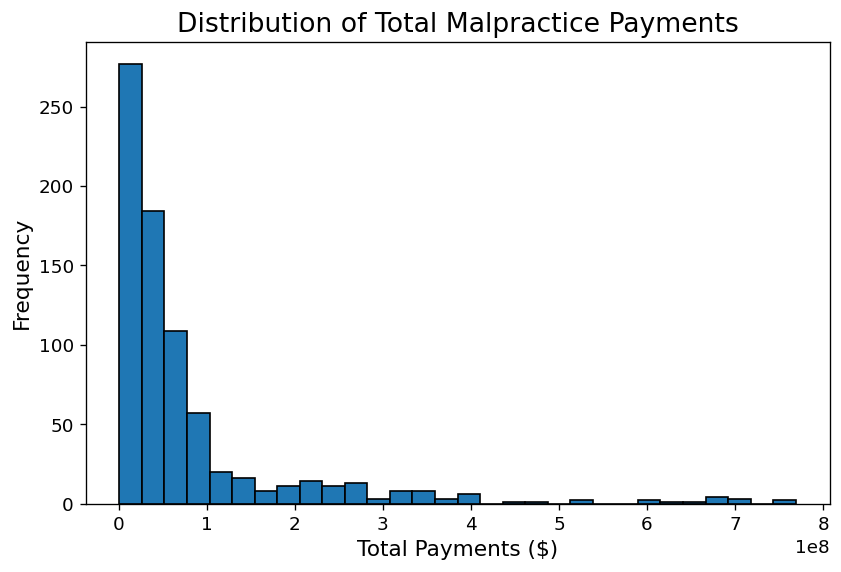

In [91]:
plt.figure(figsize = (8, 5))

plt.hist(df["total_payments"], bins = 30, edgecolor = "black")

plt.title("Distribution of Total Malpractice Payments")
plt.xlabel("Total Payments ($)")
plt.ylabel("Frequency")

plt.show()

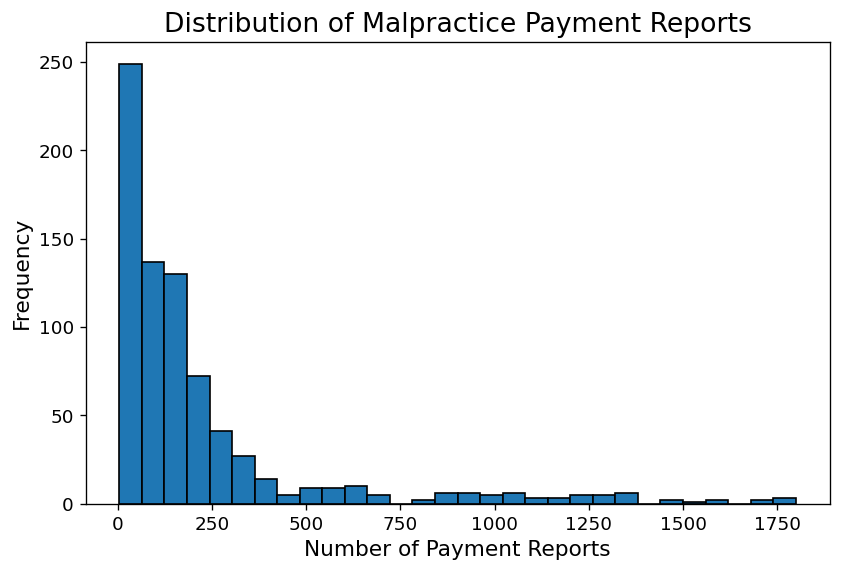

In [92]:
plt.figure(figsize = (8, 5))

plt.hist(df["payment_reports"], bins = 30, edgecolor = "black")

plt.title("Distribution of Malpractice Payment Reports")
plt.xlabel("Number of Payment Reports")
plt.ylabel("Frequency")

plt.show()

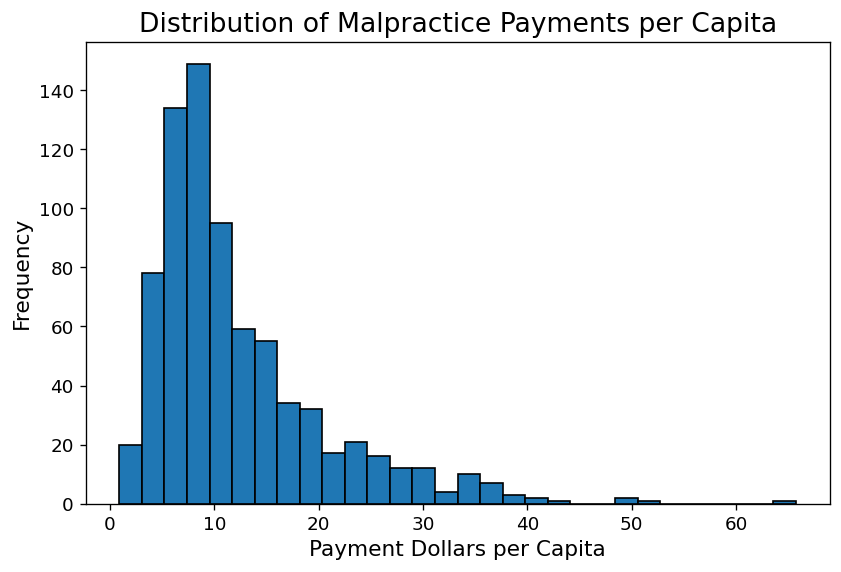

In [93]:
plt.figure(figsize = (8, 5))

plt.hist(df["payment_dollars_per_capita"], bins = 30, edgecolor = "black")

plt.title("Distribution of Malpractice Payments per Capita")
plt.xlabel("Payment Dollars per Capita")
plt.ylabel("Frequency")

plt.show()

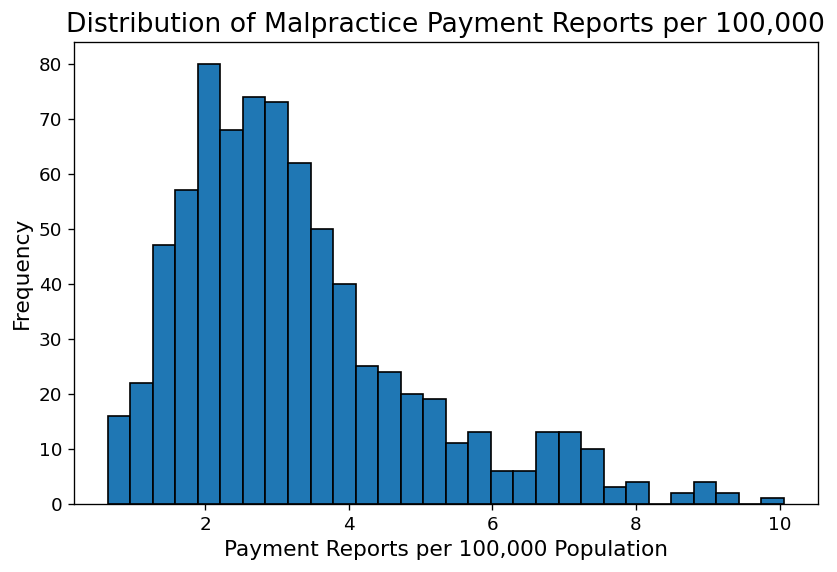

In [94]:
plt.figure(figsize = (8, 5))

plt.hist(df["payment_reports_per_100k"], bins = 30, edgecolor = "black")

plt.title("Distribution of Malpractice Payment Reports per 100,000")
plt.xlabel("Payment Reports per 100,000 Population")
plt.ylabel("Frequency")

plt.show()

## Model 1: Two-Way Fixed-Effects Panel

### model prep

In [95]:
fe_cost_vars = [
    "state",
    "year",
    "payment_dollars_per_capita",
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_written",
    "premiums_earned",
    "losses",
    "defense_costs",
    "loss_ratio"
]

fe_cost_df = df[fe_cost_vars].copy()

print(fe_cost_df.shape)
fe_cost_df.head()

(765, 11)


,state,year,payment_dollars_per_capita,median_household_income,poverty_rate,education_rate,premiums_written,premiums_earned,losses,defense_costs,loss_ratio
0,AK,2011,8.869619,67825,10.455394,26.367043,22703036.0,22569754.0,5283794.0,4437422.0,43.07
1,AK,2012,9.490816,67712,10.117271,28.008110,22107229.0,21852515.0,3583030.0,4453763.0,36.78
2,AK,2013,5.542569,72237,9.329040,27.971573,22443385.0,22176485.0,-1901825.0,3572261.0,7.53
3,AK,2014,9.609077,71583,11.233721,28.004790,23415271.0,22537843.0,5810998.0,5399730.0,49.74
4,AK,2015,10.240706,73355,10.340680,29.693114,23547386.0,23146743.0,2093624.0,4770763.0,29.66


In [96]:
fe_cost_df["log_payment_dollars_per_capita"] = np.log(
    fe_cost_df["payment_dollars_per_capita"]
)

print(
    fe_cost_df["log_payment_dollars_per_capita"].describe()
)

print(
    "Skewness:",
    fe_cost_df["log_payment_dollars_per_capita"].skew()
)

count    765.000000
mean       2.310188
std        0.636954
min       -0.115632
25%        1.921930
50%        2.258749
75%        2.727935
max        4.185608
Name: log_payment_dollars_per_capita, dtype: float64
Skewness: -0.1136076897237547


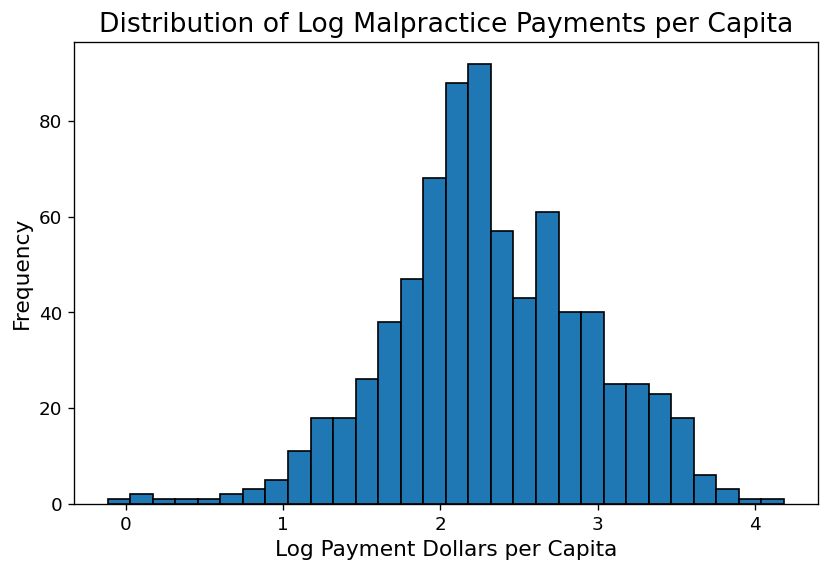

In [97]:
plt.figure(figsize = (8, 5))

plt.hist(
    fe_cost_df["log_payment_dollars_per_capita"],
    bins = 30,
    edgecolor = "black"
)

plt.title("Distribution of Log Malpractice Payments per Capita")
plt.xlabel("Log Payment Dollars per Capita")
plt.ylabel("Frequency")

plt.savefig(
    f"{FIGURE_FOLDER}/fe_log_payment_distribution.png",
    bbox_inches = "tight"
)

plt.show()

### Log-Transformed Malpractice Payments per Capita

The original malpractice payment variables showed substantial positive skew, with a small number of state-years reporting much larger payment amounts than the majority of observations. Converting payment dollars per capita to the natural logarithm substantially reduced this skew, producing a distribution that was approximately symmetric. The skewness decreased from 1.776 for the untransformed variable to approximately -0.114 after transformation. This suggests that the log-transformed outcome is more appropriate for the fixed-effects regression and reduces the influence of unusually high-payment state-years. The transformed variable was therefore used as the dependent variable for the fixed-effects cost model.

## Predictor Selection and Multicollinearity

In [98]:
fe_candidate_predictors = [
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_written",
    "premiums_earned",
    "losses",
    "defense_costs",
    "loss_ratio"
]

fe_corr_matrix = fe_cost_df[fe_candidate_predictors].corr()

fe_corr_matrix.round(2)

,median_household_income,poverty_rate,education_rate,premiums_written,premiums_earned,losses,defense_costs,loss_ratio
median_household_income,1.00,-0.72,0.80,0.18,0.17,0.21,0.13,0.14
poverty_rate,-0.72,1.00,-0.55,0.01,0.01,-0.03,0.04,-0.09
education_rate,0.80,-0.55,1.00,0.18,0.18,0.20,0.14,0.08
premiums_written,0.18,0.01,0.18,1.00,1.00,0.96,0.97,0.08
premiums_earned,0.17,0.01,0.18,1.00,1.00,0.96,0.97,0.07
losses,0.21,-0.03,0.20,0.96,0.96,1.00,0.94,0.22
defense_costs,0.13,0.04,0.14,0.97,0.97,0.94,1.00,0.14
loss_ratio,0.14,-0.09,0.08,0.08,0.07,0.22,0.14,1.00


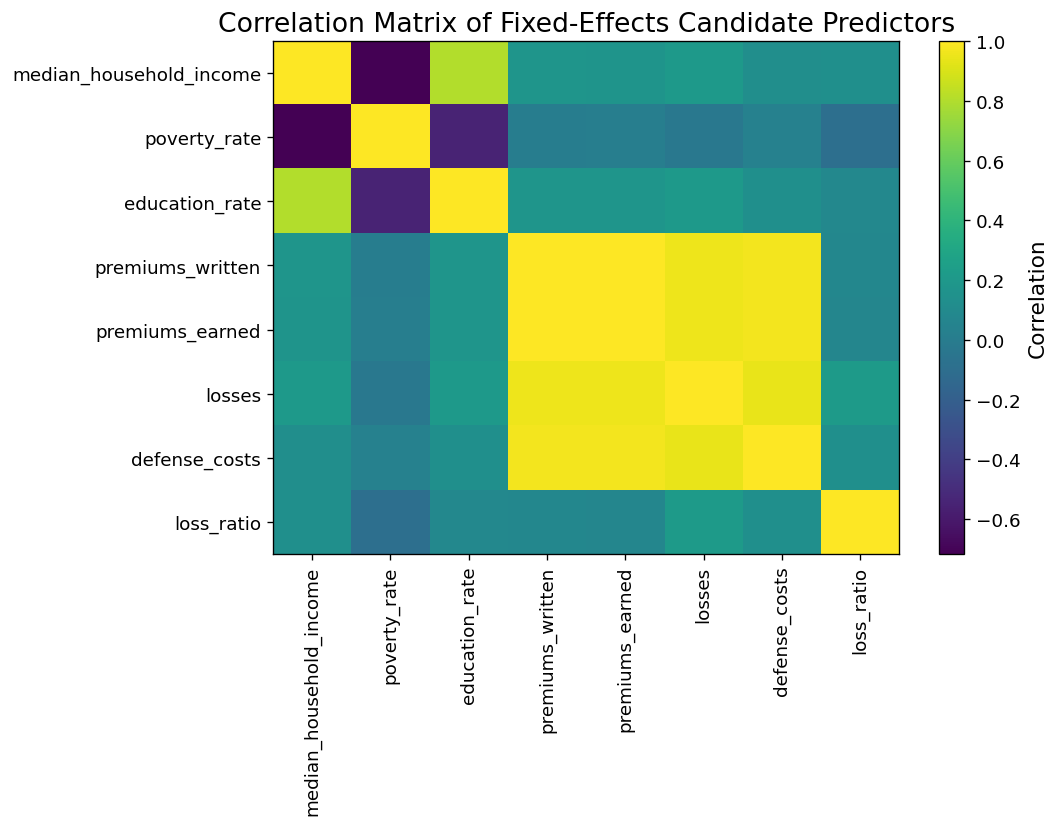

In [99]:
plt.figure(figsize = (9, 7))

plt.imshow(fe_corr_matrix, aspect = "auto")
plt.colorbar(label = "Correlation")

plt.xticks(
    range(len(fe_candidate_predictors)),
    fe_candidate_predictors,
    rotation = 90
)

plt.yticks(
    range(len(fe_candidate_predictors)),
    fe_candidate_predictors
)

plt.title("Correlation Matrix of Fixed-Effects Candidate Predictors")
plt.tight_layout()

plt.show()

In [100]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [101]:
#create predictor matrix for VIF
X_fe_vif = fe_cost_df[fe_candidate_predictors].copy()

#calculate VIF for each predictor
fe_vif = pd.DataFrame()

fe_vif["Variable"] = X_fe_vif.columns
fe_vif["VIF"] = [
    variance_inflation_factor(X_fe_vif.values, i)
    for i in range(X_fe_vif.shape[1])
]

fe_vif.sort_values("VIF", ascending = False)

,Variable,VIF
3,premiums_written,1898.629937
4,premiums_earned,1887.639351
2,education_rate,64.726367
0,median_household_income,58.526897
6,defense_costs,26.054731
5,losses,22.080251
1,poverty_rate,8.787420
7,loss_ratio,7.078946


In [102]:
from statsmodels.tools.tools import add_constant

In [103]:
# Add constant to predictor matrix
X_fe_vif_const = add_constant(X_fe_vif)

# Recalculate VIF
fe_vif_const = pd.DataFrame()

fe_vif_const["Variable"] = X_fe_vif_const.columns
fe_vif_const["VIF"] = [
    variance_inflation_factor(X_fe_vif_const.values, i)
    for i in range(X_fe_vif_const.shape[1])
]

# Exclude the constant from the displayed results
fe_vif_const = fe_vif_const[
    fe_vif_const["Variable"] != "const"
]

fe_vif_const.sort_values("VIF", ascending = False)

,Variable,VIF
4,premiums_written,1261.396221
5,premiums_earned,1254.218070
7,defense_costs,18.058046
6,losses,16.354163
1,median_household_income,4.454148
3,education_rate,2.903009
2,poverty_rate,2.168029
8,loss_ratio,1.427646


In [104]:
fe_predictors = [
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_earned",
    "defense_costs",
    "loss_ratio"
]

X_fe_final = fe_cost_df[fe_predictors].copy()
X_fe_final = add_constant(X_fe_final)

In [105]:
fe_vif_final = pd.DataFrame()

fe_vif_final["Variable"] = X_fe_final.columns
fe_vif_final["VIF"] = [
    variance_inflation_factor(X_fe_final.values, i)
    for i in range(X_fe_final.shape[1])
]

fe_vif_final = fe_vif_final[
    fe_vif_final["Variable"] != "const"
]

fe_vif_final.sort_values("VIF", ascending = False)

,Variable,VIF
4,premiums_earned,17.941911
5,defense_costs,17.858496
1,median_household_income,4.252270
3,education_rate,2.838984
2,poverty_rate,2.150856
6,loss_ratio,1.119769


In [106]:
fe_predictors = [
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "defense_costs",
    "loss_ratio"
]

X_fe_final = fe_cost_df[fe_predictors].copy()
X_fe_final = add_constant(X_fe_final)

In [107]:
fe_vif_final = pd.DataFrame()

fe_vif_final["Variable"] = X_fe_final.columns
fe_vif_final["VIF"] = [
    variance_inflation_factor(X_fe_final.values, i)
    for i in range(X_fe_final.shape[1])
]

fe_vif_final = fe_vif_final[
    fe_vif_final["Variable"] != "const"
]

fe_vif_final.sort_values("VIF", ascending = False)

,Variable,VIF
1,median_household_income,4.185230
3,education_rate,2.836684
2,poverty_rate,2.142986
4,defense_costs,1.073231
5,loss_ratio,1.038086


In [119]:
# format final vif table for saving
fe_vif_display = fe_vif_final.copy()

fe_vif_display["VIF"] = fe_vif_display["VIF"].map(
    lambda x: f"{x:.3f}"
)

fe_vif_display = fe_vif_display.set_index("Variable")

save_table(
    fe_vif_display,
    "fe_final_vif.png"
)

### Predictor Selection and Multicollinearity

Initial testing identified substantial multicollinearity among several insurance-related predictors. Premiums written and premiums earned were almost perfectly correlated, while losses and defense costs were also strongly associated with the premium variables. The predictor set was therefore reduced to median household income, poverty rate, education rate, defense costs, and loss ratio. In the final specification, all variance inflation factors were below 5, with the highest VIF approximately 4.19 for median household income. This indicates that the retained predictors provide sufficiently distinct information for inclusion in the fixed-effects model.

### Fixed-Effects Model

In [108]:
import statsmodels.formula.api as smf

In [109]:
fe_formula = """
log_payment_dollars_per_capita ~
median_household_income +
poverty_rate +
education_rate +
defense_costs +
loss_ratio +
C(state) +
C(year)
"""

fe_model = smf.ols(
    formula=fe_formula,
    data=fe_cost_df
).fit()

print(fe_model.summary())

                                  OLS Regression Results                                  
Dep. Variable:     log_payment_dollars_per_capita   R-squared:                       0.709
Model:                                        OLS   Adj. R-squared:                  0.680
Method:                             Least Squares   F-statistic:                     24.55
Date:                            Sun, 08 Nov 2026   Prob (F-statistic):          6.49e-144
Time:                                    19:40:23   Log-Likelihood:                -267.70
No. Observations:                             765   AIC:                             675.4
Df Residuals:                                 695   BIC:                             1000.
Df Model:                                      69                                         
Covariance Type:                        nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975

In [110]:
# clustered by state
fe_model_clustered = smf.ols(
    formula=fe_formula,
    data=fe_cost_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": fe_cost_df["state"]
    }
)

print(fe_model_clustered.summary())

                                  OLS Regression Results                                  
Dep. Variable:     log_payment_dollars_per_capita   R-squared:                       0.709
Model:                                        OLS   Adj. R-squared:                  0.680
Method:                             Least Squares   F-statistic:                     77.96
Date:                            Sun, 08 Nov 2026   Prob (F-statistic):           1.46e-30
Time:                                    19:40:23   Log-Likelihood:                -267.70
No. Observations:                             765   AIC:                             675.4
Df Residuals:                                 695   BIC:                             1000.
Df Model:                                      69                                         
Covariance Type:                          cluster                                         
                              coef    std err          z      P>|z|      [0.025      0.975

/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 69, but rank is 19
  warnings.warn('covariance of constraints does not have full '


### Fixed-Effects Results

In [111]:
fe_results = pd.DataFrame({
    "Coefficient": fe_model_clustered.params[fe_predictors],
    "Std_Error": fe_model_clustered.bse[fe_predictors],
    "p_value": fe_model_clustered.pvalues[fe_predictors],
    "CI_Lower": fe_model_clustered.conf_int().loc[fe_predictors, 0],
    "CI_Upper": fe_model_clustered.conf_int().loc[fe_predictors, 1]
})

fe_results.round(4)

,Coefficient,Std_Error,p_value,CI_Lower,CI_Upper
median_household_income,-0.0000,0.0000,0.1857,-0.0000,0.0000
poverty_rate,-0.0336,0.0241,0.1637,-0.0808,0.0137
education_rate,-0.0288,0.0270,0.2847,-0.0817,0.0240
defense_costs,0.0000,0.0000,0.6178,-0.0000,0.0000
loss_ratio,0.0012,0.0012,0.3134,-0.0011,0.0034


In [118]:
save_table(
    fe_results_display,
    "fe_model_results.png"
)

### Fixed-Effects Cost Model Results

The fixed-effects model examined changes in log malpractice payment dollars per capita while controlling for differences across states and years. The full model produced an R-squared of 0.709 and an adjusted R-squared of 0.680, indicating that the predictors together with the state and year fixed effects accounted for a substantial portion of variation in malpractice payment costs. After standard errors were clustered by state, none of the five substantive predictors were statistically significant at the 0.05 level. Median household income, poverty rate, and education rate had negative estimated associations with malpractice payments per capita, while defense costs and loss ratio had positive estimated associations, but the confidence intervals for each included zero. These findings suggest that within-state changes in the selected socioeconomic and insurance measures did not independently predict malpractice payment costs over the study period after state-specific and nationwide year effects were accounted for.

### Fixed-Effects Model Diagnostics

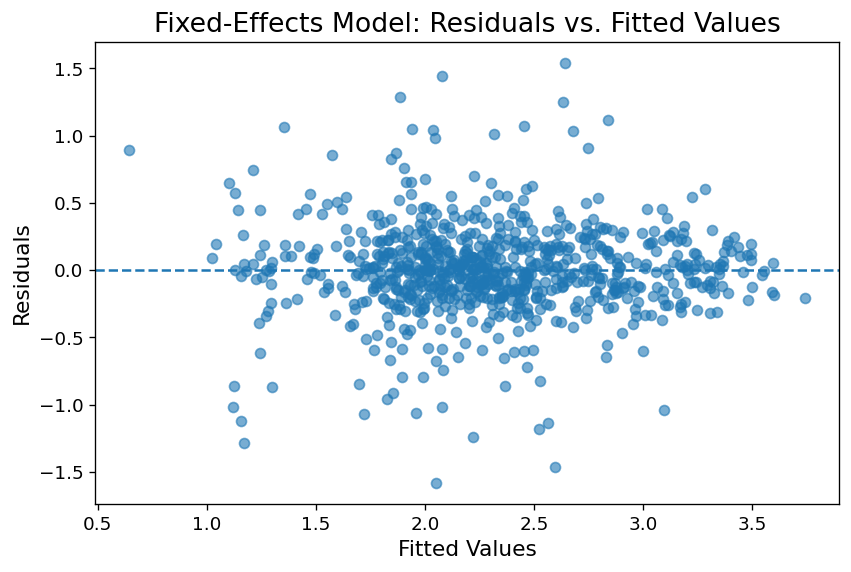

In [112]:
#residuals vs fitted values

fe_fitted = fe_model_clustered.fittedvalues
fe_residuals = fe_model_clustered.resid

plt.figure(figsize = (8, 5))

plt.scatter(fe_fitted, fe_residuals, alpha = 0.6)

plt.axhline(y = 0, linestyle = "--")

plt.title("Fixed-Effects Model: Residuals vs. Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.savefig(
    f"{FIGURE_FOLDER}/fe_residuals_vs_fitted.png",
    bbox_inches = "tight"
)

plt.show()

plt.show()

### Residuals vs. Fitted Values

The residuals-versus-fitted plot shows observations distributed around zero without a strong curved pattern, providing no clear evidence of a major nonlinear relationship omitted from the model. Residual variation appears somewhat greater near the middle of the fitted-value range, while observations with larger fitted values are more tightly concentrated around zero. State-clustered standard errors were used to provide more robust inference in the presence of repeated observations within states. Overall, the residual pattern does not indicate a severe functional-form problem requiring the fixed-effects specification to be rejected.

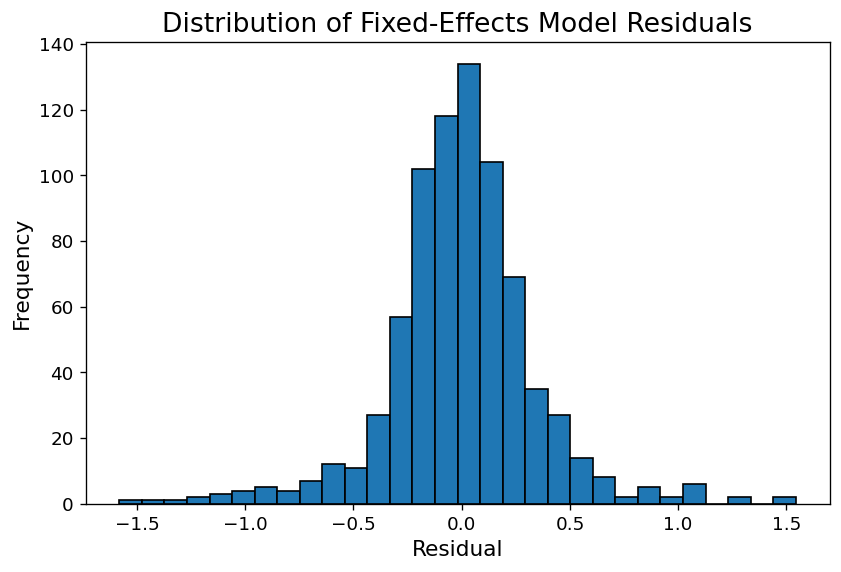

In [113]:
#residual distribution
plt.figure(figsize = (8, 5))

plt.hist(
    fe_residuals,
    bins = 30,
    edgecolor = "black"
)

plt.title("Distribution of Fixed-Effects Model Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.savefig(
    f"{FIGURE_FOLDER}/fe_residual_distribution.png",
    bbox_inches = "tight"
)

plt.show()

### Residual Distribution

The residual histogram is centered near zero and is approximately symmetric, although the distribution contains heavier tails than would be expected under perfect normality. The Q-Q plot similarly shows that most observations near the center of the distribution follow the theoretical normal pattern reasonably closely, while observations in both tails depart from the reference line. These results indicate that residual normality is imperfect and that several state-year observations exhibit unusually large positive or negative deviations from model predictions. Because the analysis uses state-clustered standard errors and the panel contains 765 observations, these departures do not by themselves invalidate the model, but they should be considered when interpreting the estimates.

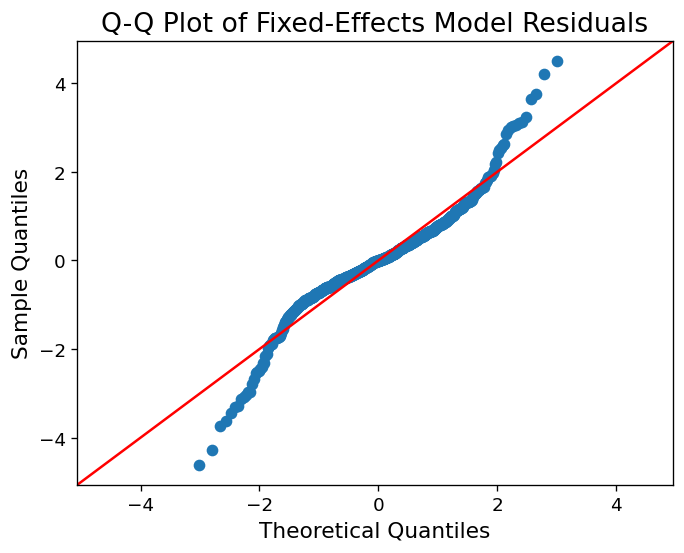

In [114]:
#q-q plot

import statsmodels.api as sm

sm.qqplot(
    fe_residuals,
    line="45",
    fit=True
)

plt.title("Q-Q Plot of Fixed-Effects Model Residuals")

plt.savefig(
    f"{FIGURE_FOLDER}/fe_qq_plot.png",
    bbox_inches = "tight"
)

plt.show()

### Residual Distribution

The residual histogram is centered near zero and is approximately symmetric, although the distribution contains heavier tails than would be expected under perfect normality. The Q-Q plot similarly shows that most observations near the center of the distribution follow the theoretical normal pattern reasonably closely, while observations in both tails depart from the reference line. These results indicate that residual normality is imperfect and that several state-year observations exhibit unusually large positive or negative deviations from model predictions. Because the analysis uses state-clustered standard errors and the panel contains 765 observations, these departures do not by themselves invalidate the model, but they should be considered when interpreting the estimates.

In [115]:
#largest residuals

fe_diagnostics = fe_cost_df[
    ["state", "year", "log_payment_dollars_per_capita"]
].copy()

fe_diagnostics["fitted"] = fe_fitted
fe_diagnostics["residual"] = fe_residuals
fe_diagnostics["abs_residual"] = abs(fe_residuals)

fe_diagnostics.sort_values(
    "abs_residual",
    ascending=False
).head(10)

,state,year,log_payment_dollars_per_capita,fitted,residual,abs_residual
761,WY,2022,0.468082,2.049616,-1.581534,1.581534
8,AK,2019,4.185608,2.642260,1.543349,1.543349
13,AK,2024,1.131615,2.597166,-1.465551,1.465551
623,SD,2019,3.522875,2.076749,1.446126,1.446126
618,SD,2014,3.175925,1.884852,1.291072,1.291072
427,ND,2018,-0.115632,1.170318,-1.285949,1.285949
177,HI,2023,3.887097,2.632746,1.254351,1.254351
763,WY,2024,0.975483,2.218110,-1.242627,1.242627
112,DC,2018,1.340564,2.523594,-1.183030,1.183030
329,ME,2025,1.430662,2.565029,-1.134366,1.134366


In [116]:
# format fixed-effects results for display
fe_results_display = fe_results.copy()

fe_results_display["Coefficient"] = fe_results_display["Coefficient"].map(
    lambda x: f"{x:.4g}"
)

fe_results_display["Std_Error"] = fe_results_display["Std_Error"].map(
    lambda x: f"{x:.4g}"
)

fe_results_display["p_value"] = fe_results_display["p_value"].map(
    lambda x: f"{x:.4f}"
)

fe_results_display["CI_Lower"] = fe_results_display["CI_Lower"].map(
    lambda x: f"{x:.4g}"
)

fe_results_display["CI_Upper"] = fe_results_display["CI_Upper"].map(
    lambda x: f"{x:.4g}"
)

fe_results_display

,Coefficient,Std_Error,p_value,CI_Lower,CI_Upper
median_household_income,-1.147e-05,8.666e-06,0.1857,-2.845e-05,5.517e-06
poverty_rate,-0.03356,0.0241,0.1637,-0.08079,0.01367
education_rate,-0.02883,0.02695,0.2847,-0.08165,0.02399
defense_costs,3.6e-10,7.213e-10,0.6178,-1.054e-09,1.774e-09
loss_ratio,0.001163,0.001154,0.3134,-0.001098,0.003425


In [120]:
# prepare largest residuals table for saving
fe_residuals_display = (
    fe_diagnostics
    .sort_values("abs_residual", ascending = False)
    .head(10)
    .copy()
)

fe_residuals_display = fe_residuals_display[
    [
        "state",
        "year",
        "log_payment_dollars_per_capita",
        "fitted",
        "residual",
        "abs_residual"
    ]
]

# round numeric values for display
fe_residuals_display[
    [
        "log_payment_dollars_per_capita",
        "fitted",
        "residual",
        "abs_residual"
    ]
] = fe_residuals_display[
    [
        "log_payment_dollars_per_capita",
        "fitted",
        "residual",
        "abs_residual"
    ]
].round(3)

# rename columns for presentation
fe_residuals_display = fe_residuals_display.rename(
    columns = {
        "state": "State",
        "year": "Year",
        "log_payment_dollars_per_capita": "Log Payment/Capita",
        "fitted": "Fitted",
        "residual": "Residual",
        "abs_residual": "Absolute Residual"
    }
)

save_table(
    fe_residuals_display,
    "fe_largest_residuals.png"
)

### Largest Model Residuals

The largest absolute residuals were concentrated primarily among relatively small-population states, including Wyoming, Alaska, South Dakota, North Dakota, and Hawaii. Wyoming in 2022 produced the largest negative residual, while Alaska in 2019 produced the largest positive residual. This pattern suggests that malpractice payment costs in smaller states may experience greater year-to-year volatility, as a relatively small number of unusual claims or payments can have a larger effect on per-capita measures. These observations were retained because they represent valid state-year data rather than identified data errors. Their presence highlights meaningful geographic and temporal variation that is not fully captured by the predictors included in the fixed-effects model.

### Fixed-Effects Modeling Approach

The malpractice cost analysis used a state-year panel containing 51 jurisdictions observed annually from 2011 through 2025. Because observations from the same state are repeated over time, a fixed-effects regression was used to account for systematic differences between states that remain relatively stable across the study period. State fixed effects control for these time-invariant differences, while year fixed effects account for nationwide changes or events affecting all states during a particular year. Malpractice payment dollars per capita were log-transformed before modeling because the original outcome was strongly right-skewed, and the transformation produced a substantially more symmetric distribution. Candidate predictors were evaluated for multicollinearity using correlations and variance inflation factors (VIF), resulting in a final specification containing median household income, poverty rate, education rate, defense costs, and loss ratio. Standard errors were clustered by state because observations within the same state may remain correlated across years even after including state fixed effects. This approach therefore focuses primarily on whether changes within a state over time are associated with changes in malpractice costs, while controlling for stable state characteristics and common national year effects.

## Model 2: Malpractice Claim Frequency Model

### Model-Specific Data Preparation

In [121]:
# create count model dataset
count_vars = [
    "state",
    "year",
    "payment_reports",
    "population",
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_written",
    "premiums_earned",
    "losses",
    "defense_costs",
    "loss_ratio"
]

count_df = df[count_vars].copy()

print(count_df.shape)
count_df.head()

(765, 12)


,state,year,payment_reports,population,median_household_income,poverty_rate,education_rate,premiums_written,premiums_earned,losses,defense_costs,loss_ratio
0,AK,2011,17,722128.0,67825,10.455394,26.367043,22703036.0,22569754.0,5283794.0,4437422.0,43.07
1,AK,2012,18,730443.0,67712,10.117271,28.008110,22107229.0,21852515.0,3583030.0,4453763.0,36.78
2,AK,2013,15,737068.0,72237,9.329040,27.971573,22443385.0,22176485.0,-1901825.0,3572261.0,7.53
3,AK,2014,22,736283.0,71583,11.233721,28.004790,23415271.0,22537843.0,5810998.0,5399730.0,49.74
4,AK,2015,19,737498.0,73355,10.340680,29.693114,23547386.0,23146743.0,2093624.0,4770763.0,29.66


In [122]:
# summarize malpractice payment reports
count_df["payment_reports"].describe()

count     765.000000
mean      223.996078
std       312.535541
min         5.000000
25%        51.000000
50%       124.000000
75%       229.000000
max      1799.000000
Name: payment_reports, dtype: float64

In [123]:
# compare count mean and variance
count_mean = count_df["payment_reports"].mean()
count_variance = count_df["payment_reports"].var()

print("Mean:", count_mean)
print("Variance:", count_variance)
print("Variance / Mean:", count_variance / count_mean)

Mean: 223.99607843137255
Variance: 97678.46464428703
Variance / Mean: 436.0722086222306


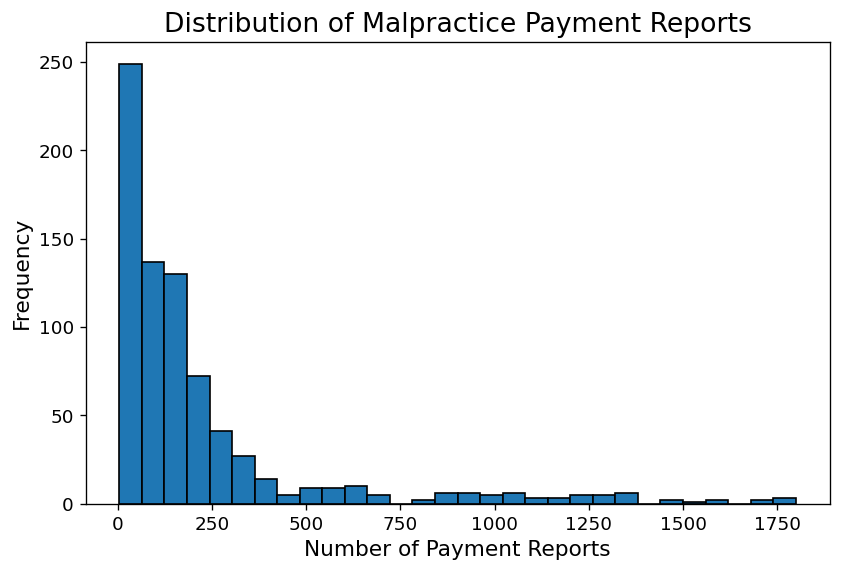

In [124]:
# plot payment report distribution
plt.figure(figsize = (8, 5))

plt.hist(
    count_df["payment_reports"],
    bins = 30,
    edgecolor = "black"
)

plt.title("Distribution of Malpractice Payment Reports")
plt.xlabel("Number of Payment Reports")
plt.ylabel("Frequency")

plt.savefig(
    f"{FIGURE_FOLDER}/count_payment_reports_distribution.png",
    bbox_inches = "tight"
)

plt.show()

In [125]:
# check zero payment-report observations
zero_count = (count_df["payment_reports"] == 0).sum()
zero_percent = (
    zero_count / len(count_df)
) * 100

print("Zero-count observations:", zero_count)
print("Percent zero:", round(zero_percent, 2))

Zero-count observations: 0
Percent zero: 0.0


In [126]:
# create population exposure offset
count_df["log_population"] = np.log(
    count_df["population"]
)

count_df[
    ["state", "year", "payment_reports", "population", "log_population"]
].head()

,state,year,payment_reports,population,log_population
0,AK,2011,17,722128.0,13.489958
1,AK,2012,18,730443.0,13.501406
2,AK,2013,15,737068.0,13.510435
3,AK,2014,22,736283.0,13.509370
4,AK,2015,19,737498.0,13.511019


In [127]:
# define candidate count model predictors
count_candidate_predictors = [
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_written",
    "premiums_earned",
    "losses",
    "defense_costs",
    "loss_ratio"
]

count_corr_matrix = count_df[
    count_candidate_predictors
].corr()

count_corr_matrix.round(2)

,median_household_income,poverty_rate,education_rate,premiums_written,premiums_earned,losses,defense_costs,loss_ratio
median_household_income,1.00,-0.72,0.80,0.18,0.17,0.21,0.13,0.14
poverty_rate,-0.72,1.00,-0.55,0.01,0.01,-0.03,0.04,-0.09
education_rate,0.80,-0.55,1.00,0.18,0.18,0.20,0.14,0.08
premiums_written,0.18,0.01,0.18,1.00,1.00,0.96,0.97,0.08
premiums_earned,0.17,0.01,0.18,1.00,1.00,0.96,0.97,0.07
losses,0.21,-0.03,0.20,0.96,0.96,1.00,0.94,0.22
defense_costs,0.13,0.04,0.14,0.97,0.97,0.94,1.00,0.14
loss_ratio,0.14,-0.09,0.08,0.08,0.07,0.22,0.14,1.00


In [128]:
# calculate vif for candidate predictors
X_count_vif = count_df[
    count_candidate_predictors
].copy()

X_count_vif = add_constant(X_count_vif)

count_vif = pd.DataFrame()

count_vif["Variable"] = X_count_vif.columns
count_vif["VIF"] = [
    variance_inflation_factor(X_count_vif.values, i)
    for i in range(X_count_vif.shape[1])
]

count_vif = count_vif[
    count_vif["Variable"] != "const"
]

count_vif.sort_values("VIF", ascending = False)

,Variable,VIF
4,premiums_written,1261.396221
5,premiums_earned,1254.218070
7,defense_costs,18.058046
6,losses,16.354163
1,median_household_income,4.454148
3,education_rate,2.903009
2,poverty_rate,2.168029
8,loss_ratio,1.427646


In [129]:
# define final count model predictors
count_predictors = [
    "median_household_income",
    "poverty_rate",
    "education_rate",
    "premiums_earned",
    "loss_ratio"
]

X_count_final = count_df[count_predictors].copy()
X_count_final = add_constant(X_count_final)

In [130]:
# calculate final count model vif
count_vif_final = pd.DataFrame()

count_vif_final["Variable"] = X_count_final.columns
count_vif_final["VIF"] = [
    variance_inflation_factor(X_count_final.values, i)
    for i in range(X_count_final.shape[1])
]

count_vif_final = count_vif_final[
    count_vif_final["Variable"] != "const"
]

count_vif_final.sort_values("VIF", ascending = False)

,Variable,VIF
1,median_household_income,4.215384
3,education_rate,2.838353
2,poverty_rate,2.150481
4,premiums_earned,1.078244
5,loss_ratio,1.025015


In [155]:
# format final count model vif table for saving
count_vif_display = count_vif_final.copy()

count_vif_display = count_vif_display[
    count_vif_display["Variable"] != "const"
].copy()

count_vif_display["Variable"] = count_vif_display[
    "Variable"
].replace(
    {
        "median_household_income": "Median Household Income",
        "poverty_rate": "Poverty Rate",
        "education_rate": "Education Rate",
        "premiums_earned": "Premiums Earned",
        "loss_ratio": "Loss Ratio"
    }
)

count_vif_display["VIF"] = count_vif_display[
    "VIF"
].map(
    lambda x: f"{x:.3f}"
)

count_vif_display = count_vif_display.set_index(
    "Variable"
)

save_table(
    count_vif_display,
    "nb_final_vif.png"
)

### Poisson Model and Overdispersion Test

In [131]:
# define poisson model
poisson_formula = """
payment_reports ~
median_household_income +
poverty_rate +
education_rate +
premiums_earned +
loss_ratio +
C(state) +
C(year)
"""

poisson_model = smf.glm(
    formula = poisson_formula,
    data = count_df,
    family = sm.families.Poisson(),
    offset = count_df["log_population"]
).fit()

print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:        payment_reports   No. Observations:                  765
Model:                            GLM   Df Residuals:                      695
Model Family:                 Poisson   Df Model:                           69
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3779.0
Date:                Sun, 08 Nov 2026   Deviance:                       2541.6
Time:                        19:53:19   Pearson chi2:                 2.58e+03
No. Iterations:                     9   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [132]:
# calculate poisson dispersion statistic
poisson_dispersion = (
    poisson_model.pearson_chi2 /
    poisson_model.df_resid
)

print(
    "Poisson dispersion statistic:",
    poisson_dispersion
)

Poisson dispersion statistic: 3.7156863038545183


### Negative Binomial Model

In [134]:
# fit negative binomial model
negative_binomial_model = smf.negativebinomial(
    formula = poisson_formula,
    data = count_df,
    offset = count_df["log_population"]
).fit(
    maxiter = 200
)

print(negative_binomial_model.summary())

         Current function value: nan
         Iterations: 0
         Function evaluations: 2
         Gradient evaluations: 2
                     NegativeBinomial Regression Results                      
Dep. Variable:        payment_reports   No. Observations:                  765
Model:               NegativeBinomial   Df Residuals:                      695
Method:                           MLE   Df Model:                           69
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                     nan
Time:                        19:55:19   Log-Likelihood:                    nan
converged:                      False   LL-Null:                       -4177.7
Covariance Type:            nonrobust   LLR p-value:                       nan
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                      nan        nan        nan  

/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:1567: RuntimeWarning: overflow encountered in exp
  L = np.exp(np.dot(X,params) + exposure + offset)
/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:1568: RuntimeWarning: invalid value encountered in multiply
  return -np.dot(L*X.T, X)
/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:1478: RuntimeWarning: overflow encountered in exp
  L = np.exp(np.dot(X,params) + offset + exposure)
/usr/local/lib/python3.10/dist-packages/scipy/optimize/_optimize.py:1313: OptimizeWarning: NaN result encountered.
  res = _minimize_bfgs(f, x0, args, fprime, callback=callback, **opts)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607

In [135]:
# compare poisson and negative binomial model fit
model_comparison = pd.DataFrame({
    "Model": [
        "Poisson",
        "Negative Binomial"
    ],
    "AIC": [
        poisson_model.aic,
        negative_binomial_model.aic
    ]
})

model_comparison

,Model,AIC
0,Poisson,7697.935066
1,Negative Binomial,NaN


In [136]:
# compare model log-likelihood
print(
    "Poisson log-likelihood:",
    poisson_model.llf
)

print(
    "Negative Binomial log-likelihood:",
    negative_binomial_model.llf
)

Poisson log-likelihood: -3778.9675331879107
Negative Binomial log-likelihood: nan


need to rescale the predictors

In [137]:
# rescale predictors for negative binomial model
count_df["income_10k"] = (
    count_df["median_household_income"] / 10000
)

count_df["premiums_earned_millions"] = (
    count_df["premiums_earned"] / 1000000
)

count_df[
    [
        "income_10k",
        "poverty_rate",
        "education_rate",
        "premiums_earned_millions",
        "loss_ratio"
    ]
].describe()

,income_10k,poverty_rate,education_rate,premiums_earned_millions,loss_ratio
count,765.000000,765.000000,765.000000,765.000000,765.000000
mean,6.448717,13.267817,32.507488,204.448001,66.231556
std,1.511691,3.156270,6.997223,284.671742,32.848717
min,3.691900,6.158960,18.470203,9.076775,-347.420000
25%,5.250400,10.854108,27.701737,46.744634,47.570000
50%,6.210600,12.665965,31.719013,101.719933,65.020000
75%,7.431400,15.540320,36.274817,232.817726,81.300000
max,10.970700,24.153531,65.944185,1795.873110,228.480000


In [138]:
# define rescaled count model formula
count_formula = """
payment_reports ~
income_10k +
poverty_rate +
education_rate +
premiums_earned_millions +
loss_ratio +
C(state) +
C(year)
"""

In [139]:
# refit poisson model with rescaled predictors
poisson_model_scaled = smf.glm(
    formula = count_formula,
    data = count_df,
    family = sm.families.Poisson(),
    offset = count_df["log_population"]
).fit()

print(
    "Poisson dispersion statistic:",
    poisson_model_scaled.pearson_chi2 /
    poisson_model_scaled.df_resid
)

print(
    "Poisson AIC:",
    poisson_model_scaled.aic
)

Poisson dispersion statistic: 3.715686393390559
Poisson AIC: 7697.935066370371


In [140]:
# fit negative binomial model with rescaled predictors
negative_binomial_model = smf.negativebinomial(
    formula = count_formula,
    data = count_df,
    offset = count_df["log_population"]
).fit(
    method = "bfgs",
    maxiter = 1000,
    disp = False
)

print(negative_binomial_model.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:        payment_reports   No. Observations:                  765
Model:               NegativeBinomial   Df Residuals:                      695
Method:                           MLE   Df Model:                           69
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                -0.05656
Time:                        19:58:05   Log-Likelihood:                -4414.0
converged:                      False   LL-Null:                       -4177.7
Covariance Type:            nonrobust   LLR p-value:                     1.000
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -9.2082        nan        nan        nan         nan         nan
C(state)[T.AL]              -0.6741        nan        nan        nan         nan         

/usr/local/lib/python3.10/dist-packages/statsmodels/discrete/discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [141]:
# check negative binomial convergence
print(
    "Converged:",
    negative_binomial_model.mle_retvals["converged"]
)

print(
    "Negative Binomial AIC:",
    negative_binomial_model.aic
)

print(
    "Negative Binomial log-likelihood:",
    negative_binomial_model.llf
)

Converged: False
Negative Binomial AIC: 8969.90675975469
Negative Binomial log-likelihood: -4413.953379877345


### GLM negative binomial

because the model kept failing to converge, we are moving on to using a GLM implementation

In [142]:
# estimate negative binomial alpha from poisson residuals
poisson_mu = poisson_model_scaled.fittedvalues

alpha_numerator = (
    (
        count_df["payment_reports"] - poisson_mu
    ) ** 2
    - poisson_mu
)

alpha_denominator = poisson_mu ** 2

alpha_estimate = (
    alpha_numerator.sum() /
    alpha_denominator.sum()
)

print(
    "Estimated alpha:",
    alpha_estimate
)

Estimated alpha: 0.007029592092148178


In [143]:
# fit glm negative binomial model
negative_binomial_glm = smf.glm(
    formula = count_formula,
    data = count_df,
    family = sm.families.NegativeBinomial(
        alpha = alpha_estimate
    ),
    offset = count_df["log_population"]
).fit()

print(negative_binomial_glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:        payment_reports   No. Observations:                  765
Model:                            GLM   Df Residuals:                      695
Model Family:        NegativeBinomial   Df Model:                           69
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3329.8
Date:                Sun, 08 Nov 2026   Deviance:                       1079.7
Time:                        20:00:47   Pearson chi2:                 1.11e+03
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [144]:
# check negative binomial model fit
print(
    "Estimated alpha:",
    alpha_estimate
)

print(
    "Negative Binomial AIC:",
    negative_binomial_glm.aic
)

print(
    "Negative Binomial log-likelihood:",
    negative_binomial_glm.llf
)

print(
    "Negative Binomial deviance:",
    negative_binomial_glm.deviance
)

print(
    "Negative Binomial Pearson dispersion:",
    negative_binomial_glm.pearson_chi2 /
    negative_binomial_glm.df_resid
)

Estimated alpha: 0.007029592092148178
Negative Binomial AIC: 6799.574487167232
Negative Binomial log-likelihood: -3329.787243583616
Negative Binomial deviance: 1079.6640929597102
Negative Binomial Pearson dispersion: 1.590208266351251


In [145]:
# clustered negative binomial

# fit negative binomial model with state-clustered standard errors
negative_binomial_clustered = smf.glm(
    formula = count_formula,
    data = count_df,
    family = sm.families.NegativeBinomial(
        alpha = alpha_estimate
    ),
    offset = count_df["log_population"]
).fit(
    cov_type = "cluster",
    cov_kwds = {
        "groups": count_df["state"]
    }
)

print(negative_binomial_clustered.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:        payment_reports   No. Observations:                  765
Model:                            GLM   Df Residuals:                      695
Model Family:        NegativeBinomial   Df Model:                           69
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3329.8
Date:                Sun, 08 Nov 2026   Deviance:                       1079.7
Time:                        20:02:30   Pearson chi2:                 1.11e+03
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [146]:
# create incidence rate ratio results table
count_results = pd.DataFrame({
    "Coefficient": negative_binomial_clustered.params[
        [
            "income_10k",
            "poverty_rate",
            "education_rate",
            "premiums_earned_millions",
            "loss_ratio"
        ]
    ],
    "Std_Error": negative_binomial_clustered.bse[
        [
            "income_10k",
            "poverty_rate",
            "education_rate",
            "premiums_earned_millions",
            "loss_ratio"
        ]
    ],
    "p_value": negative_binomial_clustered.pvalues[
        [
            "income_10k",
            "poverty_rate",
            "education_rate",
            "premiums_earned_millions",
            "loss_ratio"
        ]
    ]
})

count_results["IRR"] = np.exp(
    count_results["Coefficient"]
)

count_results["CI_Lower"] = np.exp(
    negative_binomial_clustered.conf_int().loc[
        count_results.index, 0
    ]
)

count_results["CI_Upper"] = np.exp(
    negative_binomial_clustered.conf_int().loc[
        count_results.index, 1
    ]
)

count_results.round(4)

,Coefficient,Std_Error,p_value,IRR,CI_Lower,CI_Upper
income_10k,-0.0764,0.0451,0.0900,0.9264,0.8480,1.0120
poverty_rate,-0.0191,0.0153,0.2117,0.9811,0.9521,1.0109
education_rate,-0.0243,0.0175,0.1647,0.9760,0.9432,1.0100
premiums_earned_millions,0.0003,0.0002,0.0360,1.0003,1.0000,1.0006
loss_ratio,0.0008,0.0004,0.0257,1.0008,1.0001,1.0016


In [154]:
# format negative binomial results table for saving
count_results_display = count_results.copy()

count_results_display = count_results_display.rename(
    index = {
        "income_10k": "Median Income ($10k)",
        "poverty_rate": "Poverty Rate",
        "education_rate": "Education Rate",
        "premiums_earned_millions": "Premiums Earned ($1M)",
        "loss_ratio": "Loss Ratio"
    }
)

count_results_display["Coefficient"] = count_results_display[
    "Coefficient"
].map(
    lambda x: f"{x:.4f}"
)

count_results_display["Std_Error"] = count_results_display[
    "Std_Error"
].map(
    lambda x: f"{x:.4f}"
)

count_results_display["p_value"] = count_results_display[
    "p_value"
].map(
    lambda x: f"{x:.4f}"
)

count_results_display["IRR"] = count_results_display[
    "IRR"
].map(
    lambda x: f"{x:.4f}"
)

count_results_display["CI_Lower"] = count_results_display[
    "CI_Lower"
].map(
    lambda x: f"{x:.4f}"
)

count_results_display["CI_Upper"] = count_results_display[
    "CI_Upper"
].map(
    lambda x: f"{x:.4f}"
)

save_table(
    count_results_display,
    "nb_model_results.png"
)

In [147]:
# calculate interpretable incidence rate ratios
premium_coef = negative_binomial_clustered.params[
    "premiums_earned_millions"
]

loss_ratio_coef = negative_binomial_clustered.params[
    "loss_ratio"
]

premium_irr_100m = np.exp(
    premium_coef * 100
)

loss_ratio_irr_10 = np.exp(
    loss_ratio_coef * 10
)

print(
    "IRR for $100 million increase in premiums earned:",
    premium_irr_100m
)

print(
    "Percent change:",
    (premium_irr_100m - 1) * 100
)

print()

print(
    "IRR for 10-point increase in loss ratio:",
    loss_ratio_irr_10
)

print(
    "Percent change:",
    (loss_ratio_irr_10 - 1) * 100
)

IRR for $100 million increase in premiums earned: 1.032389723292989
Percent change: 3.238972329298906

IRR for 10-point increase in loss ratio: 1.0084008279688683
Percent change: 0.8400827968868319


In [148]:
# calculate fitted values and pearson residuals
count_fitted = negative_binomial_clustered.fittedvalues
count_pearson_residuals = negative_binomial_clustered.resid_pearson

print(
    "Pearson residual mean:",
    count_pearson_residuals.mean()
)

print(
    "Pearson residual standard deviation:",
    count_pearson_residuals.std()
)

Pearson residual mean: -0.00013473904015400153
Pearson residual standard deviation: 1.2027426833439858


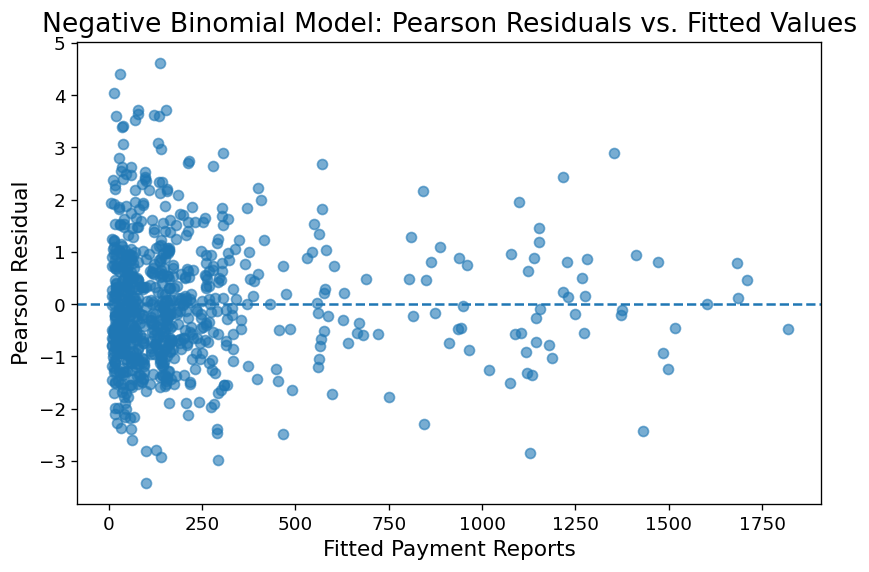

In [149]:
# plot pearson residuals vs fitted values
plt.figure(figsize = (8, 5))

plt.scatter(
    count_fitted,
    count_pearson_residuals,
    alpha = 0.6
)

plt.axhline(
    y = 0,
    linestyle = "--"
)

plt.title("Negative Binomial Model: Pearson Residuals vs. Fitted Values")
plt.xlabel("Fitted Payment Reports")
plt.ylabel("Pearson Residual")

plt.savefig(
    f"{FIGURE_FOLDER}/nb_pearson_residuals_vs_fitted.png",
    bbox_inches = "tight"
)

plt.show()

### Pearson Residuals vs. Fitted Values

The Pearson residuals are generally distributed around zero across the range of fitted malpractice payment-report counts, without a strong systematic curve. Most observations are concentrated at lower fitted counts, reflecting the large number of state-years with relatively few malpractice payment reports. The spread of residuals is greater among these lower-count observations, while residuals at higher fitted values are generally more concentrated around zero. Several observations have relatively large positive or negative residuals, indicating state-years where the observed number of reports differed substantially from the model prediction. However, the plot does not show an obvious systematic pattern suggesting that the model consistently overpredicts or underpredicts across the fitted-value range. Overall, the residual pattern supports the Negative Binomial specification while also indicating that some state-year variation remains unexplained.

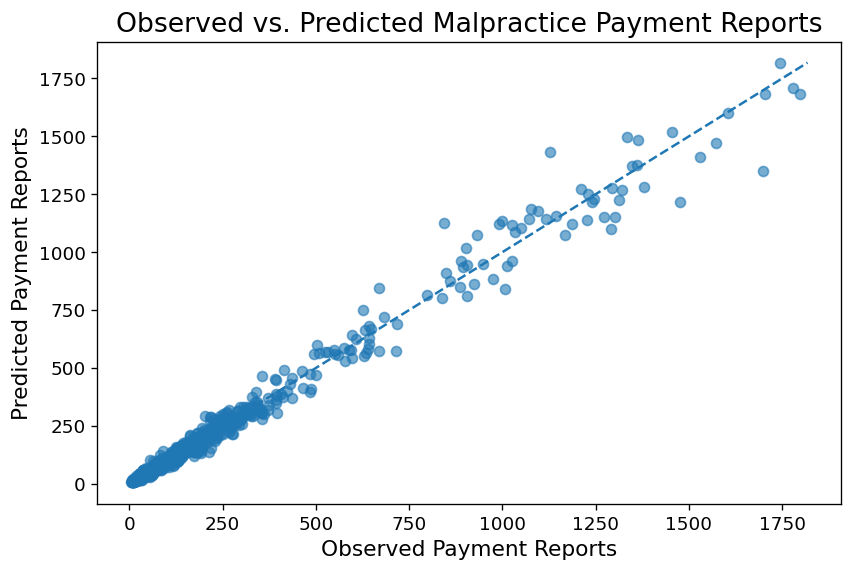

In [150]:
# plot observed vs predicted payment reports
plt.figure(figsize = (8, 5))

plt.scatter(
    count_df["payment_reports"],
    count_fitted,
    alpha = 0.6
)

min_count = min(
    count_df["payment_reports"].min(),
    count_fitted.min()
)

max_count = max(
    count_df["payment_reports"].max(),
    count_fitted.max()
)

plt.plot(
    [min_count, max_count],
    [min_count, max_count],
    linestyle = "--"
)

plt.title("Observed vs. Predicted Malpractice Payment Reports")
plt.xlabel("Observed Payment Reports")
plt.ylabel("Predicted Payment Reports")

plt.savefig(
    f"{FIGURE_FOLDER}/nb_observed_vs_predicted.png",
    bbox_inches = "tight"
)

plt.show()

### Observed vs. Predicted Payment Reports

The observed-versus-predicted plot shows a strong correspondence between the actual number of malpractice payment reports and the counts predicted by the Negative Binomial model. Most observations fall relatively close to the diagonal reference line, indicating that the model reproduces the overall variation in claim frequency across state-years reasonably well. This relationship remains visible across both low-count states and state-years with more than 1,000 payment reports. Some deviations become more noticeable among the highest-count observations, demonstrating that the model does not perfectly predict every state-year. Nevertheless, the close overall alignment suggests that incorporating population exposure, socioeconomic and insurance predictors, and state and year effects captures a substantial amount of the geographic and temporal variation in malpractice payment-report frequency. The model therefore appears useful for describing broad differences in malpractice report rates while still leaving some state-year-specific variation unexplained.

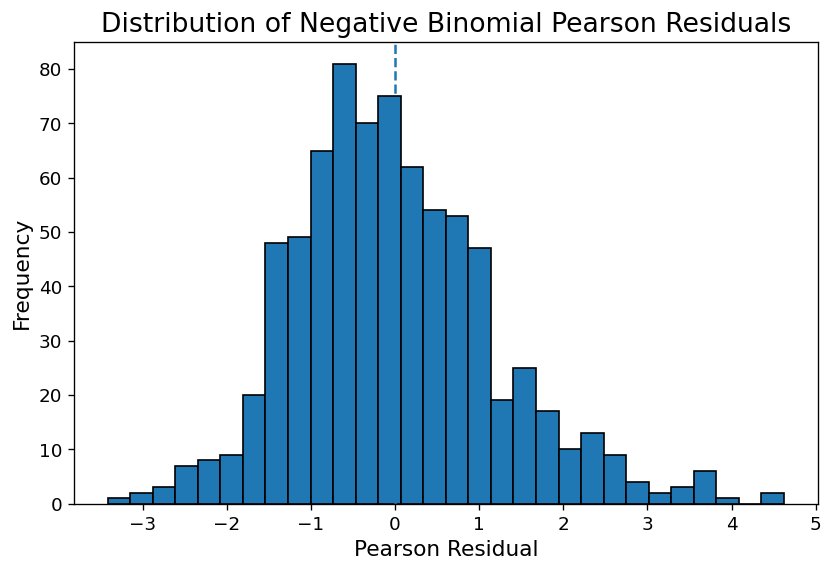

In [151]:
# plot pearson residual distribution
plt.figure(figsize = (8, 5))

plt.hist(
    count_pearson_residuals,
    bins = 30,
    edgecolor = "black"
)

plt.axvline(
    x = 0,
    linestyle = "--"
)

plt.title("Distribution of Negative Binomial Pearson Residuals")
plt.xlabel("Pearson Residual")
plt.ylabel("Frequency")

plt.savefig(
    f"{FIGURE_FOLDER}/nb_pearson_residual_distribution.png",
    bbox_inches = "tight"
)

plt.show()

### Pearson Residual Distribution

The distribution of Pearson residuals is centered near zero, although it shows some positive skew and contains observations in both tails. Most residuals fall within approximately -2 to +2, indicating that the majority of state-year observations are reasonably consistent with the counts expected by the model. A smaller number of observations have substantially larger residuals, particularly on the positive side, representing state-years in which malpractice payment reports were considerably higher than predicted. Unlike an ordinary least-squares regression, a Negative Binomial GLM does not require its residuals to follow a normal distribution, so departures from normality are not themselves evidence that the model is invalid. The remaining tail behavior is consistent with the substantial heterogeneity present in malpractice claim-frequency data. Combined with the reduction in Pearson dispersion from approximately 3.72 under Poisson to 1.59 under the Negative Binomial specification, the residual distribution supports the use of Negative Binomial rather than Poisson regression.

In [152]:
# identify largest pearson residuals
count_diagnostics = count_df[
    [
        "state",
        "year",
        "payment_reports",
        "population"
    ]
].copy()

count_diagnostics["predicted_reports"] = count_fitted
count_diagnostics["pearson_residual"] = count_pearson_residuals
count_diagnostics["abs_pearson_residual"] = abs(
    count_pearson_residuals
)

count_diagnostics.sort_values(
    "abs_pearson_residual",
    ascending = False
).head(10)

,state,year,payment_reports,population,predicted_reports,pearson_residual,abs_pearson_residual
493,NM,2024,214,2126774.0,137.844659,4.622569,4.622569
105,DC,2011,56,619800.0,29.605382,4.413429,4.413429
703,VT,2024,32,646521.0,15.346163,4.038951,4.038951
29,AL,2025,121,5193088.0,79.555796,3.721095,3.721095
630,TN,2011,220,6399291.0,153.575118,3.716923,3.716923
376,MS,2012,117,2983816.0,77.289403,3.635963,3.635963
735,WV,2011,174,1856301.0,120.051092,3.626016,3.626016
618,SD,2014,35,849129.0,18.510000,3.605418,3.605418
494,NM,2025,193,2125498.0,134.778916,3.593662,3.593662
188,IA,2019,107,3155070.0,70.732190,3.524278,3.524278


In [156]:
# prepare largest pearson residuals table for saving
count_residuals_display = (
    count_diagnostics
    .sort_values(
        "abs_pearson_residual",
        ascending = False
    )
    .head(10)
    .copy()
)

count_residuals_display = count_residuals_display[
    [
        "state",
        "year",
        "payment_reports",
        "predicted_reports",
        "pearson_residual",
        "abs_pearson_residual"
    ]
]

# round numeric values for display
count_residuals_display[
    [
        "predicted_reports",
        "pearson_residual",
        "abs_pearson_residual"
    ]
] = count_residuals_display[
    [
        "predicted_reports",
        "pearson_residual",
        "abs_pearson_residual"
    ]
].round(3)

# rename columns for presentation
count_residuals_display = count_residuals_display.rename(
    columns = {
        "state": "State",
        "year": "Year",
        "payment_reports": "Observed Reports",
        "predicted_reports": "Predicted Reports",
        "pearson_residual": "Pearson Residual",
        "abs_pearson_residual": "Absolute Residual"
    }
)

save_table(
    count_residuals_display,
    "nb_largest_residuals.png"
)

### Largest Pearson Residuals

The largest Pearson residuals identify state-years in which the observed number of malpractice payment reports was substantially greater than predicted by the model. The largest residual occurred in New Mexico in 2024, with 214 observed reports compared with approximately 138 predicted reports, followed by the District of Columbia in 2011 and Vermont in 2024. Several other state-years, including Alabama in 2025, Tennessee in 2011, Mississippi in 2012, and West Virginia in 2011, also showed unusually large positive deviations. These observations do not necessarily represent data errors and were retained because they may reflect genuine state-specific changes or circumstances not represented by the predictors included in the model. The presence of these residuals indicates that population, socioeconomic characteristics, insurance measures, and fixed effects do not account for every short-term fluctuation in malpractice payment-report frequency. These unusually high-report state-years may therefore warrant additional investigation if geographic or temporal anomalies become important to the broader malpractice analysis.

In [153]:
# count large pearson residuals
pearson_over_2 = (
    abs(count_pearson_residuals) > 2
).sum()

pearson_over_3 = (
    abs(count_pearson_residuals) > 3
).sum()

print(
    "Observations with |Pearson residual| > 2:",
    pearson_over_2
)

print(
    "Percent:",
    round(
        pearson_over_2 / len(count_df) * 100,
        2
    )
)

print()

print(
    "Observations with |Pearson residual| > 3:",
    pearson_over_3
)

print(
    "Percent:",
    round(
        pearson_over_3 / len(count_df) * 100,
        2
    )
)

Observations with |Pearson residual| > 2: 69
Percent: 9.02

Observations with |Pearson residual| > 3: 15
Percent: 1.96


### Extreme Pearson Residuals

Of the 765 state-year observations, 69 (9.02%) had absolute Pearson residuals greater than 2, while only 15 (1.96%) had absolute residuals greater than 3. This indicates that most observations were not extreme relative to the counts predicted by the Negative Binomial model, although a modest number of state-years exhibited substantial deviations. The relatively small proportion exceeding an absolute residual of 3 suggests that severe prediction errors were concentrated in a limited subset of the panel rather than occurring throughout the dataset. These observations were retained because large residuals alone do not demonstrate that an observation is erroneous or inappropriate for analysis. Instead, they illustrate the degree of state-year-specific variation that remains after accounting for the modeled predictors, population exposure, and fixed effects. Overall, the residual counts do not indicate a widespread failure of the Negative Binomial specification.

### Count Modeling Approach

Malpractice payment-report frequency was modeled separately because the number of payment reports is count data rather than a continuous financial outcome. A Poisson regression was initially fitted using the number of payment reports as the dependent variable, with population included as a log exposure offset so that states with different population sizes could be compared on an underlying report-rate basis. The raw count data showed substantial overdispersion, with a variance-to-mean ratio of approximately 436, although this alone was not used to reject the Poisson model because differences in population and other predictors could account for some of that variation. After population exposure, socioeconomic and insurance predictors, state effects, and year effects were incorporated, the fitted Poisson model still produced a Pearson dispersion statistic of approximately 3.72, indicating substantial conditional overdispersion. A Negative Binomial model was therefore selected because it allows the conditional variance to exceed the conditional mean. Initial maximum-likelihood Negative Binomial specifications failed to converge, even after rescaling the predictors, so a GLM Negative Binomial implementation was used with an overdispersion parameter estimated from the Poisson residuals. The resulting Negative Binomial GLM reduced the Pearson dispersion statistic to approximately 1.59, substantially improving the treatment of overdispersion relative to Poisson. Finally, standard errors were clustered by state to account for repeated observations within states, and the resulting coefficients were converted to incidence rate ratios (IRRs) to provide more interpretable measures of changes in expected malpractice report rates.

## Model 5: K-Means Clustering

### Model-Specific Data Preparation

In [157]:
# define k-means variables
kmeans_vars = [
    "state",
    "payment_reports_per_100k",
    "payment_dollars_per_capita",
    "loss_ratio",
    "median_household_income",
    "population",
    "education_rate"
]

kmeans_df = df[kmeans_vars].copy()

print(kmeans_df.shape)
kmeans_df.head()

(765, 7)


,state,payment_reports_per_100k,payment_dollars_per_capita,loss_ratio,median_household_income,population,education_rate
0,AK,2.354153,8.869619,43.07,67825,722128.0,26.367043
1,AK,2.464258,9.490816,36.78,67712,730443.0,28.008110
2,AK,2.035090,5.542569,7.53,72237,737068.0,27.971573
3,AK,2.987982,9.609077,49.74,71583,736283.0,28.004790
4,AK,2.576278,10.240706,29.66,73355,737498.0,29.693114


In [158]:
# aggregate malpractice characteristics by state
kmeans_state_df = (
    kmeans_df
    .groupby("state", as_index = False)
    .mean()
)

print(kmeans_state_df.shape)
kmeans_state_df.head()

(51, 7)


,state,payment_reports_per_100k,payment_dollars_per_capita,loss_ratio,median_household_income,population,education_rate
0,AK,2.513440,16.011347,51.993333,78388.066667,7.347251e+05,30.129362
1,AL,1.556871,7.405838,63.432667,51565.666667,4.953443e+06,26.172358
2,AR,2.066745,6.872199,70.028667,48959.466667,3.012410e+06,23.682388
3,AZ,2.912668,10.074781,54.521333,61745.800000,7.073690e+06,30.371265
4,CA,3.020677,6.661138,69.590000,76989.466667,3.897135e+07,34.434136


In [159]:
# summarize state-level clustering features
kmeans_features = [
    "payment_reports_per_100k",
    "payment_dollars_per_capita",
    "loss_ratio",
    "median_household_income",
    "population",
    "education_rate"
]

kmeans_state_df[
    kmeans_features
].describe().T

,count,mean,std,min,25%,50%,75%,max
payment_reports_per_100k,51.0,3.268739e+00,1.517986e+00,1.048570,2.212844e+00,2.874740e+00,3.919920e+00,7.581083e+00
payment_dollars_per_capita,51.0,1.229377e+01,6.680141e+00,3.785599,7.596950e+00,1.008638e+01,1.504996e+01,3.298186e+01
loss_ratio,51.0,6.623156e+01,1.721836e+01,32.955333,5.764933e+01,6.613733e+01,7.507633e+01,1.318707e+02
median_household_income,51.0,6.448717e+04,1.055795e+04,45960.000000,5.748633e+04,6.231867e+04,7.314640e+04,8.634673e+04
population,51.0,6.404431e+06,7.288293e+06,580839.333333,1.795560e+06,4.473276e+06,7.263127e+06,3.897135e+07
education_rate,51.0,3.250749e+01,6.445658e+00,21.548659,2.881307e+01,3.206393e+01,3.519158e+01,5.965741e+01


In [160]:
# check skewness of clustering features
kmeans_state_df[
    kmeans_features
].skew().sort_values(
    ascending = False
)

population                    2.653150
education_rate                1.541822
payment_dollars_per_capita    1.255240
payment_reports_per_100k      1.057161
loss_ratio                    0.848714
median_household_income       0.417058
dtype: float64

transforming the skewed features to see if that fix the "large state vs small state" population skew

In [162]:
# transform skewed clustering features
kmeans_state_df["log_population"] = np.log(
    kmeans_state_df["population"]
)

kmeans_state_df["log_payment_dollars_per_capita"] = np.log(
    kmeans_state_df["payment_dollars_per_capita"]
)

In [163]:
# check transformed feature skewness
transformed_features = [
    "payment_reports_per_100k",
    "log_payment_dollars_per_capita",
    "loss_ratio",
    "median_household_income",
    "log_population",
    "education_rate"
]

kmeans_state_df[
    transformed_features
].skew().sort_values(
    ascending = False
)

education_rate                    1.541822
payment_reports_per_100k          1.057161
loss_ratio                        0.848714
median_household_income           0.417058
log_payment_dollars_per_capita    0.167338
log_population                   -0.042806
dtype: float64

In [164]:
# import standard scaler
from sklearn.preprocessing import StandardScaler

In [165]:
# standardize clustering features
kmeans_scaler = StandardScaler()

kmeans_scaled = kmeans_scaler.fit_transform(
    kmeans_state_df[transformed_features]
)

kmeans_scaled_df = pd.DataFrame(
    kmeans_scaled,
    columns = transformed_features,
    index = kmeans_state_df["state"]
)

kmeans_scaled_df.head()

,payment_reports_per_100k,log_payment_dollars_per_capita,loss_ratio,median_household_income,log_population,education_rate
state,,,,,,
AK,-0.502518,0.779111,-0.835149,1.329730,-1.610175,-0.372621
AL,-1.138945,-0.743923,-0.164170,-1.236044,0.238930,-0.992632
AR,-0.799714,-0.891646,0.222721,-1.485347,-0.242974,-1.382778
AZ,-0.236902,-0.135983,-0.686868,-0.262234,0.584170,-0.334718
CA,-0.165041,-0.953264,0.196991,1.195943,2.237645,0.301881


In [166]:
# verify standardized feature means and standard deviations
kmeans_scaled_df.describe().T[
    ["mean", "std"]
].round(3)

,mean,std
payment_reports_per_100k,0.0,1.01
log_payment_dollars_per_capita,0.0,1.01
loss_ratio,0.0,1.01
median_household_income,0.0,1.01
log_population,0.0,1.01
education_rate,-0.0,1.01


In [167]:
# import k-means and silhouette tools
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [168]:
# evaluate possible numbers of clusters
k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans_test = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 20
    )

    cluster_labels = kmeans_test.fit_predict(
        kmeans_scaled_df
    )

    inertia_values.append(
        kmeans_test.inertia_
    )

    silhouette_values.append(
        silhouette_score(
            kmeans_scaled_df,
            cluster_labels
        )
    )

k_selection_df = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

k_selection_df

,k,Inertia,Silhouette_Score
0,2,223.103714,0.327269
1,3,185.599052,0.222919
2,4,157.507382,0.228290
3,5,138.227782,0.207336
4,6,119.211149,0.215384
5,7,105.682205,0.225168
6,8,92.002429,0.233113


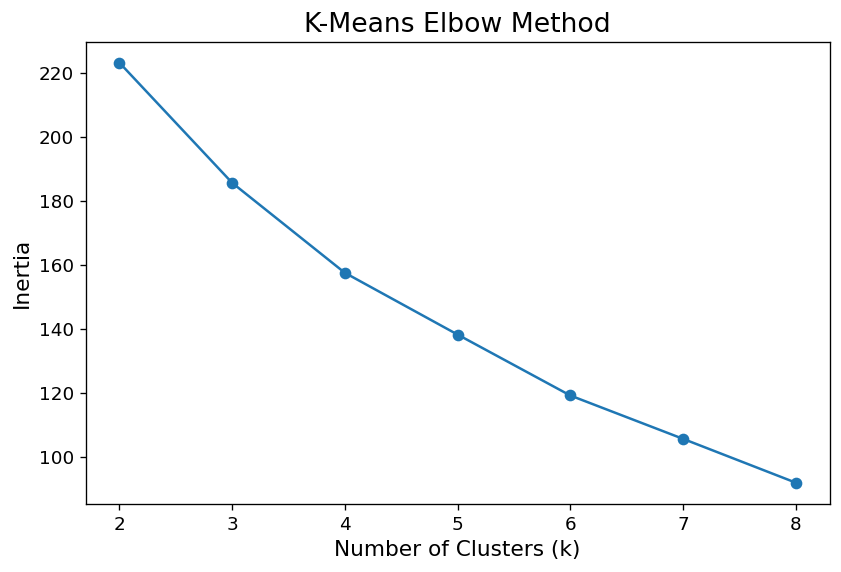

In [169]:
# plot elbow method results
plt.figure(figsize = (8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker = "o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")

plt.savefig(
    f"{FIGURE_FOLDER}/kmeans_elbow_plot.png",
    bbox_inches = "tight"
)

plt.show()

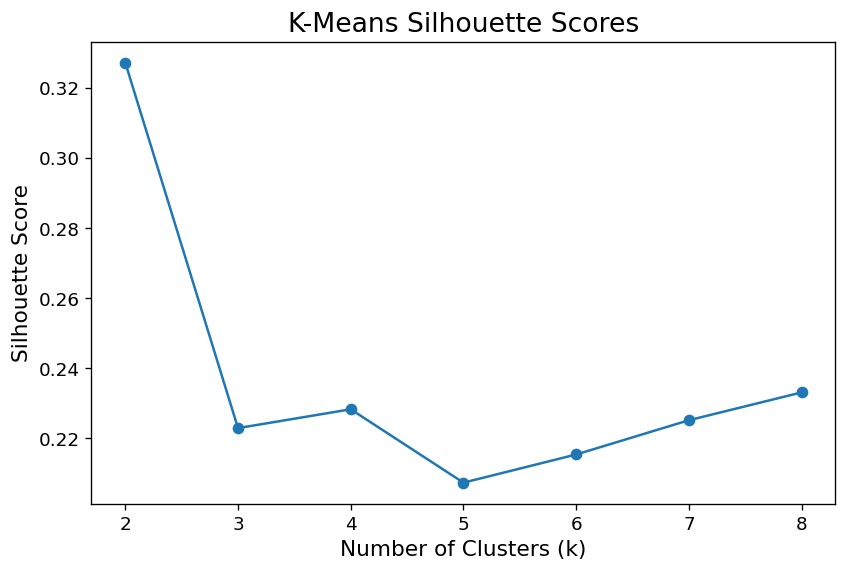

In [170]:
# plot silhouette scores
plt.figure(figsize = (8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker = "o"
)

plt.title("K-Means Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")

plt.savefig(
    f"{FIGURE_FOLDER}/kmeans_silhouette_plot.png",
    bbox_inches = "tight"
)

plt.show()

In [171]:
# fit final k-means model
kmeans_final = KMeans(
    n_clusters = 2,
    random_state = 42,
    n_init = 20
)

kmeans_state_df["cluster"] = kmeans_final.fit_predict(
    kmeans_scaled_df
)

kmeans_state_df[
    ["state", "cluster"]
].sort_values(
    ["cluster", "state"]
)

,state,cluster
0,AK,0
1,AL,0
2,AR,0
3,AZ,0
4,CA,0
5,CO,0
8,DE,0
9,FL,0
10,GA,0
11,HI,0


In [172]:
# check number of states in each cluster
kmeans_state_df[
    "cluster"
].value_counts().sort_index()

cluster
0    40
1    11
Name: count, dtype: int64

In [173]:
# calculate cluster profiles in original units
cluster_profiles = kmeans_state_df.groupby(
    "cluster"
)[
    [
        "payment_reports_per_100k",
        "payment_dollars_per_capita",
        "loss_ratio",
        "median_household_income",
        "population",
        "education_rate"
    ]
].mean()

cluster_profiles.round(2)

,payment_reports_per_100k,payment_dollars_per_capita,loss_ratio,median_household_income,population,education_rate
cluster,,,,,,
0,2.80,9.38,62.58,61827.86,6260599.18,30.67
1,4.96,22.90,79.52,74157.39,6927456.95,39.18


In [174]:
# calculate standardized cluster centroids
cluster_centroids = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns = transformed_features
)

cluster_centroids.index.name = "cluster"

cluster_centroids.round(2)

,payment_reports_per_100k,log_payment_dollars_per_capita,loss_ratio,median_household_income,log_population,education_rate
cluster,,,,,,
0,-0.31,-0.40,-0.21,-0.25,-0.03,-0.29
1,1.12,1.44,0.78,0.93,0.10,1.05


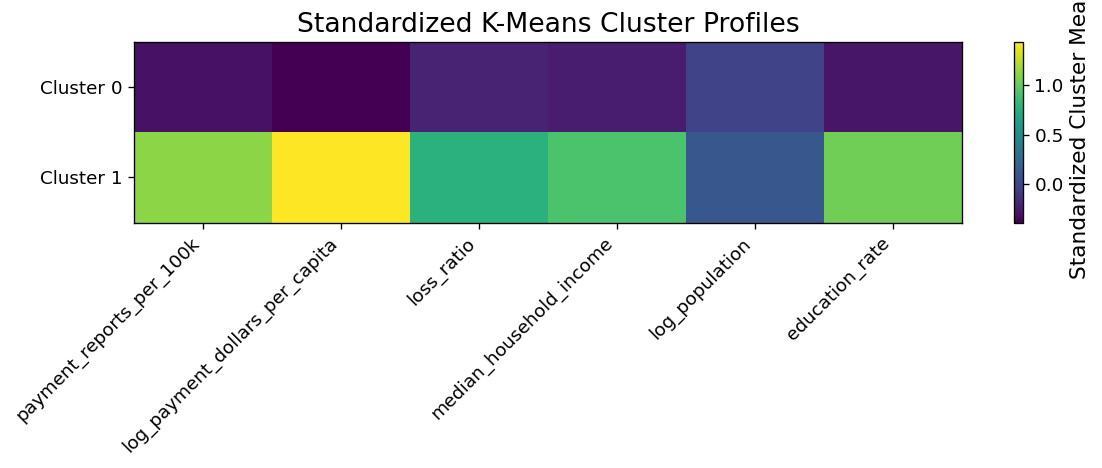

In [175]:
# plot standardized cluster profiles
plt.figure(figsize = (10, 4))

plt.imshow(
    cluster_centroids,
    aspect = "auto"
)

plt.colorbar(
    label = "Standardized Cluster Mean"
)

plt.xticks(
    range(len(transformed_features)),
    transformed_features,
    rotation = 45,
    ha = "right"
)

plt.yticks(
    range(len(cluster_centroids)),
    [
        f"Cluster {i}"
        for i in cluster_centroids.index
    ]
)

plt.title("Standardized K-Means Cluster Profiles")
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/kmeans_cluster_profiles.png",
    bbox_inches = "tight"
)

plt.show()

In [179]:
# prepare cluster profile table for saving
cluster_profiles_display = cluster_profiles.copy()

cluster_profiles_display = cluster_profiles_display.rename(
    index = cluster_names,
    columns = {
        "payment_reports_per_100k": "Reports per 100k",
        "payment_dollars_per_capita": "Payments per Capita",
        "loss_ratio": "Loss Ratio",
        "median_household_income": "Median Income",
        "population": "Population",
        "education_rate": "Education Rate"
    }
)

cluster_profiles_display = cluster_profiles_display.round(2)

save_table(
    cluster_profiles_display,
    "kmeans_cluster_profiles_table.png"
)

### K-Means Cluster Profiles

K-Means clustering identified two broad state malpractice profiles based on payment-report frequency, payment costs, loss ratio, household income, population, and education. Cluster 0 contained 40 states and was characterized by lower malpractice report frequency and payment costs, averaging approximately 2.80 payment reports per 100,000 residents and $9.38 in malpractice payments per capita. Cluster 1 contained 11 jurisdictions and showed substantially higher malpractice activity, averaging approximately 4.96 reports per 100,000 residents and $22.90 in payments per capita. States in the higher cost/frequency cluster also had higher average loss ratios, median household incomes, and education rates. Standardized cluster centroids showed that payment dollars per capita and payment-report frequency were among the strongest characteristics distinguishing the two groups, while population differed very little between the clusters. This indicates that the clustering pattern is not simply separating large states from small states and instead reflects differences in malpractice and socioeconomic characteristics. The resulting groups should be interpreted as descriptive state profiles rather than evidence that any individual characteristic causes higher malpractice costs or claim frequency.

In [176]:
# assign descriptive cluster labels
cluster_names = {
    0: "Lower Cost/Frequency",
    1: "Higher Cost/Frequency"
}

kmeans_state_df["cluster_profile"] = (
    kmeans_state_df["cluster"].map(
        cluster_names
    )
)

kmeans_state_df[
    ["state", "cluster_profile"]
].sort_values(
    ["cluster_profile", "state"]
)

,state,cluster_profile
6,CT,Higher Cost/Frequency
7,DC,Higher Cost/Frequency
14,IL,Higher Cost/Frequency
19,MA,Higher Cost/Frequency
20,MD,Higher Cost/Frequency
30,NH,Higher Cost/Frequency
31,NJ,Higher Cost/Frequency
32,NM,Higher Cost/Frequency
34,NY,Higher Cost/Frequency
38,PA,Higher Cost/Frequency


In [180]:
# prepare higher cost/frequency cluster membership table
higher_cluster_display = kmeans_state_df[
    kmeans_state_df["cluster"] == 1
][
    [
        "state",
        "payment_reports_per_100k",
        "payment_dollars_per_capita",
        "loss_ratio",
        "median_household_income",
        "education_rate"
    ]
].copy()

higher_cluster_display = higher_cluster_display.rename(
    columns = {
        "state": "State",
        "payment_reports_per_100k": "Reports per 100k",
        "payment_dollars_per_capita": "Payments per Capita",
        "loss_ratio": "Loss Ratio",
        "median_household_income": "Median Income",
        "education_rate": "Education Rate"
    }
)

higher_cluster_display[
    [
        "Reports per 100k",
        "Payments per Capita",
        "Loss Ratio",
        "Education Rate"
    ]
] = higher_cluster_display[
    [
        "Reports per 100k",
        "Payments per Capita",
        "Loss Ratio",
        "Education Rate"
    ]
].round(2)

higher_cluster_display["Median Income"] = (
    higher_cluster_display["Median Income"].round(0)
)

higher_cluster_display = higher_cluster_display.set_index(
    "State"
)

save_table(
    higher_cluster_display,
    "kmeans_higher_cluster_states.png"
)

### State Malpractice Profiles by Cluster

The state-level scatterplot shows a clear tendency for jurisdictions in the Higher Cost/Frequency cluster to have both greater malpractice payment-report frequency and higher payment dollars per capita. Most states in the Lower Cost/Frequency cluster are concentrated in the lower-left portion of the plot, while the Higher Cost/Frequency jurisdictions generally extend toward the upper-right. New York is particularly distinct, exhibiting both the highest average report frequency and the highest average payment dollars per capita among the state-level observations. Some overlap remains between the clusters, indicating that the groups are not completely separated based on these two malpractice measures alone. This is consistent with the moderate silhouette score of approximately 0.327 and reflects the fact that the K-Means solution also incorporates loss ratio, household income, population, and education. Overall, the visualization supports the interpretation of two broad malpractice profiles rather than two sharply separated categories of states.

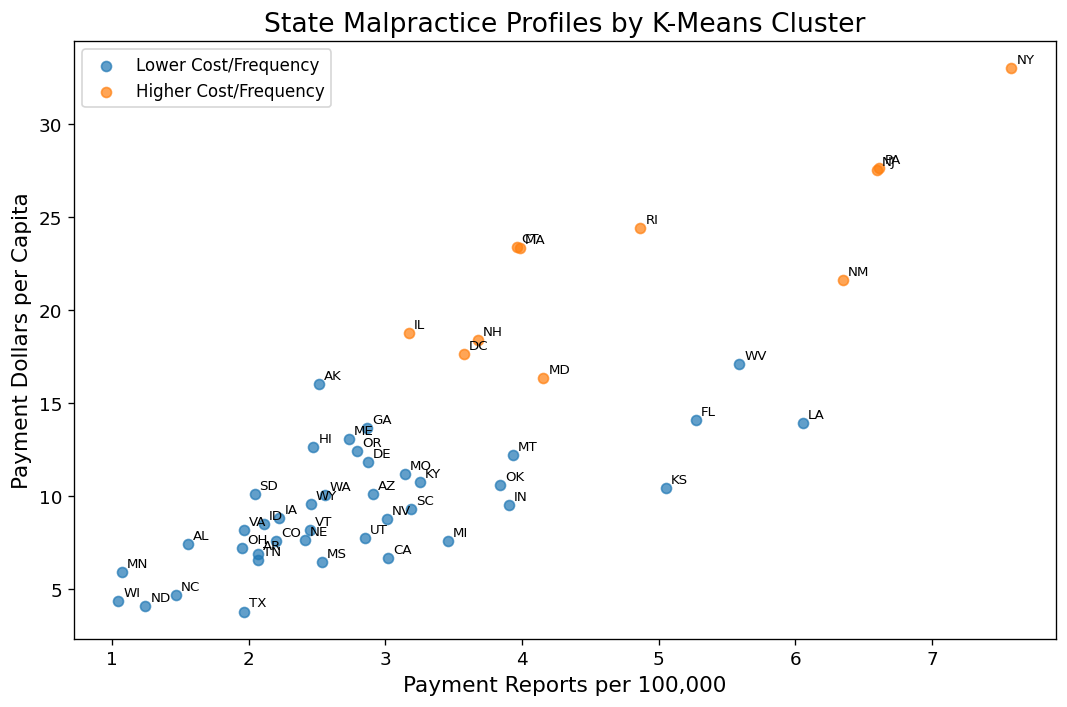

In [177]:
# plot state malpractice profiles by cluster
plt.figure(figsize = (9, 6))

for cluster in sorted(
    kmeans_state_df["cluster"].unique()
):
    cluster_data = kmeans_state_df[
        kmeans_state_df["cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["payment_reports_per_100k"],
        cluster_data["payment_dollars_per_capita"],
        label = cluster_names[cluster],
        alpha = 0.7
    )

    for _, row in cluster_data.iterrows():
        plt.annotate(
            row["state"],
            (
                row["payment_reports_per_100k"],
                row["payment_dollars_per_capita"]
            ),
            fontsize = 8,
            xytext = (3, 3),
            textcoords = "offset points"
        )

plt.title("State Malpractice Profiles by K-Means Cluster")
plt.xlabel("Payment Reports per 100,000")
plt.ylabel("Payment Dollars per Capita")
plt.legend()

plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/kmeans_state_clusters.png",
    bbox_inches = "tight"
)

plt.show()

### K-Means Results and Implications

K-Means clustering identified two broad malpractice profiles among the 51 jurisdictions based on average characteristics from 2011–2025. The Lower Cost/Frequency cluster contained 40 states, while the Higher Cost/Frequency cluster contained 11 jurisdictions: Connecticut, the District of Columbia, Illinois, Massachusetts, Maryland, New Hampshire, New Jersey, New Mexico, New York, Pennsylvania, and Rhode Island. The Higher Cost/Frequency cluster averaged 4.96 payment reports per 100,000 residents and $22.90 in malpractice payments per capita, compared with 2.80 reports and $9.38 per capita in the lower cluster. It also exhibited higher average loss ratios, median household income, and education rates, while average population differed relatively little between the two groups. The standardized cluster profiles indicate that malpractice payments per capita and payment-report frequency were the strongest distinguishing characteristics, followed by education, household income, and loss ratio. These findings provide descriptive support for the possibility that states with higher socioeconomic characteristics may also exhibit higher malpractice costs and frequency, although K-Means clustering cannot establish a causal relationship. When considered alongside the fixed-effects results, the clustering suggests that socioeconomic differences may distinguish states cross-sectionally even though changes in those socioeconomic measures within individual states were not significant predictors of malpractice payment costs over time.

### K-Means Clustering Approach

K-Means clustering was used to identify groups of states with similar overall malpractice and socioeconomic profiles without specifying a dependent variable. Because the goal was to characterize broader differences between states rather than individual state-years, the 2011–2025 panel was aggregated to one observation per jurisdiction by averaging each clustering feature across the study period. The clustering variables included malpractice payment reports per 100,000 residents, payment dollars per capita, loss ratio, median household income, population, and education rate. Population and payment dollars per capita were log-transformed because their original distributions were substantially right-skewed, reducing the influence of extreme values on the distance-based clustering procedure. All features were then standardized so that variables measured on larger numerical scales, such as population and household income, would not disproportionately influence the Euclidean distances used by K-Means. Candidate solutions ranging from two to eight clusters were evaluated using both the elbow method and silhouette scores rather than selecting the number of clusters in advance. The two-cluster solution was retained because it produced the highest silhouette score (approximately 0.327), while the elbow analysis did not provide sufficiently strong evidence for a more complex solution. This approach produced two moderately separated state profiles that could then be compared based on their malpractice, insurance, and socioeconomic characteristics.

## Model 3: Elastic Net

### Model-Specific Data Preparation

In [181]:
# define elastic net variables
elastic_predictors = [
    "payment_reports_per_100k",
    "mean_settlement_delay",
    "prac_Dentistry",
    "prac_Nursing",
    "prac_Other",
    "prac_Physician",
    "prac_Physician Assistant",
    "alleg_Anesthesia Related",
    "alleg_Behavioral Health Related",
    "alleg_Diagnosis Related",
    "alleg_Equipment/Product Related",
    "alleg_IV & Blood Products Related",
    "alleg_Medication Related",
    "alleg_Monitoring Related",
    "alleg_Obstetrics Related",
    "alleg_Other Miscellaneous",
    "alleg_Surgery Related",
    "alleg_Treatment Related",
    "outcome_Cannot Be Determined",
    "outcome_Death",
    "outcome_Emotional Injury Only",
    "outcome_Insignificant Injury",
    "outcome_Major Permanent Injury",
    "outcome_Major Temporary Injury",
    "outcome_Minor Permanent Injury",
    "outcome_Minor Temporary Injury",
    "outcome_Quadriplegic / Brain Damage / Lifelong Care",
    "outcome_Significant Permanent Injury",
    "reporting_entity_count",
    "premiums_written",
    "premiums_earned",
    "losses",
    "defense_costs",
    "loss_ratio",
    "population",
    "median_household_income",
    "poverty_rate",
    "education_rate"
]

elastic_vars = [
    "state",
    "year",
    "payment_dollars_per_capita"
] + elastic_predictors

elastic_df = df[elastic_vars].copy()

print(elastic_df.shape)
elastic_df.head()

(765, 41)


,state,year,payment_dollars_per_capita,payment_reports_per_100k,mean_settlement_delay,prac_Dentistry,prac_Nursing,prac_Other,prac_Physician,prac_Physician Assistant,...,reporting_entity_count,premiums_written,premiums_earned,losses,defense_costs,loss_ratio,population,median_household_income,poverty_rate,education_rate
0,AK,2011,8.869619,2.354153,3.294118,2,2,2,10,1,...,55,22703036.0,22569754.0,5283794.0,4437422.0,43.07,722128.0,67825,10.455394,26.367043
1,AK,2012,9.490816,2.464258,3.833333,4,2,0,11,1,...,56,22107229.0,21852515.0,3583030.0,4453763.0,36.78,730443.0,67712,10.117271,28.008110
2,AK,2013,5.542569,2.035090,4.066667,2,2,2,9,0,...,62,22443385.0,22176485.0,-1901825.0,3572261.0,7.53,737068.0,72237,9.329040,27.971573
3,AK,2014,9.609077,2.987982,4.272727,0,3,4,15,0,...,60,23415271.0,22537843.0,5810998.0,5399730.0,49.74,736283.0,71583,11.233721,28.004790
4,AK,2015,10.240706,2.576278,3.684211,2,3,0,13,1,...,64,23547386.0,23146743.0,2093624.0,4770763.0,29.66,737498.0,73355,10.340680,29.693114


In [182]:
# create elastic net target
elastic_df["log_payment_dollars_per_capita"] = np.log(
    elastic_df["payment_dollars_per_capita"]
)

elastic_df[
    "log_payment_dollars_per_capita"
].describe()

count    765.000000
mean       2.310188
std        0.636954
min       -0.115632
25%        1.921930
50%        2.258749
75%        2.727935
max        4.185608
Name: log_payment_dollars_per_capita, dtype: float64

In [183]:
# create temporal training and test sets
elastic_train = elastic_df[
    elastic_df["year"] <= 2022
].copy()

elastic_test = elastic_df[
    elastic_df["year"] >= 2023
].copy()

print(
    "Training shape:",
    elastic_train.shape
)

print(
    "Test shape:",
    elastic_test.shape
)

print(
    "Training years:",
    elastic_train["year"].min(),
    "-",
    elastic_train["year"].max()
)

print(
    "Test years:",
    elastic_test["year"].min(),
    "-",
    elastic_test["year"].max()
)

Training shape: (612, 42)
Test shape: (153, 42)
Training years: 2011 - 2022
Test years: 2023 - 2025


In [184]:
# separate predictors and target
X_train = elastic_train[
    elastic_predictors
].copy()

X_test = elastic_test[
    elastic_predictors
].copy()

y_train = elastic_train[
    "log_payment_dollars_per_capita"
].copy()

y_test = elastic_test[
    "log_payment_dollars_per_capita"
].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (612, 38)
X_test: (153, 38)
y_train: (612,)
y_test: (153,)


In [185]:
# examine elastic net predictor scales
X_train.describe().T[
    ["mean", "std", "min", "max"]
]

,mean,std,min,max
payment_reports_per_100k,3.292579e+00,1.671140e+00,6.543369e-01,9.373480e+00
mean_settlement_delay,4.376392e+00,8.244685e-01,2.500000e+00,7.729577e+00
prac_Dentistry,2.585621e+01,4.679452e+01,0.000000e+00,3.050000e+02
prac_Nursing,1.433824e+01,1.967531e+01,0.000000e+00,1.460000e+02
prac_Other,1.475490e+01,1.973778e+01,0.000000e+00,1.210000e+02
prac_Physician,1.647712e+02,2.366417e+02,2.000000e+00,1.433000e+03
prac_Physician Assistant,3.857843e+00,5.709646e+00,0.000000e+00,3.700000e+01
alleg_Anesthesia Related,5.612745e+00,8.432967e+00,0.000000e+00,6.000000e+01
alleg_Behavioral Health Related,1.361111e+00,2.041787e+00,0.000000e+00,1.400000e+01
alleg_Diagnosis Related,5.834477e+01,8.803589e+01,0.000000e+00,5.860000e+02


In [186]:
# standardize elastic net predictors
elastic_scaler = StandardScaler()

X_train_scaled = elastic_scaler.fit_transform(
    X_train
)

X_test_scaled = elastic_scaler.transform(
    X_test
)

In [187]:
# verify standardized training predictors
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns = elastic_predictors,
    index = X_train.index
)

X_train_scaled_df.describe().T[
    ["mean", "std"]
].round(3)

,mean,std
payment_reports_per_100k,0.0,1.001
mean_settlement_delay,0.0,1.001
prac_Dentistry,-0.0,1.001
prac_Nursing,0.0,1.001
prac_Other,-0.0,1.001
prac_Physician,0.0,1.001
prac_Physician Assistant,-0.0,1.001
alleg_Anesthesia Related,0.0,1.001
alleg_Behavioral Health Related,-0.0,1.001
alleg_Diagnosis Related,-0.0,1.001


In [188]:
# import elastic net tools
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit

In [189]:
# sort training data chronologically
train_order = elastic_train.sort_values(
    ["year", "state"]
).index

X_train_cv = X_train_scaled_df.loc[
    train_order
]

y_train_cv = y_train.loc[
    train_order
]

In [190]:
# create time-aware cross-validation folds
elastic_cv = TimeSeriesSplit(
    n_splits = 5
)

In [191]:
# tune elastic net model
elastic_model = ElasticNetCV(
    l1_ratio = [
        0.1,
        0.25,
        0.5,
        0.75,
        0.9,
        0.95,
        1.0
    ],
    alphas = 100,
    cv = elastic_cv,
    max_iter = 100000
)

elastic_model.fit(
    X_train_cv,
    y_train_cv
)

print(
    "Selected alpha:",
    elastic_model.alpha_
)

print(
    "Selected l1 ratio:",
    elastic_model.l1_ratio_
)

Selected alpha: 0.0068902137859031065
Selected l1 ratio: 1.0


In [192]:
# examine elastic net coefficients
elastic_coefficients = pd.DataFrame({
    "Predictor": elastic_predictors,
    "Coefficient": elastic_model.coef_
})

elastic_coefficients["Absolute_Coefficient"] = abs(
    elastic_coefficients["Coefficient"]
)

elastic_coefficients = elastic_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending = False
)

elastic_coefficients

,Predictor,Coefficient,Absolute_Coefficient
0,payment_reports_per_100k,0.416873,0.416873
30,premiums_earned,0.112930,0.112930
1,mean_settlement_delay,0.094097,0.094097
23,outcome_Major Temporary Injury,-0.091279,0.091279
16,alleg_Surgery Related,-0.072357,0.072357
34,population,-0.070109,0.070109
33,loss_ratio,0.065504,0.065504
35,median_household_income,0.062230,0.062230
37,education_rate,0.051840,0.051840
28,reporting_entity_count,0.029962,0.029962


In [201]:
# prepare retained elastic net coefficient table for saving
elastic_coefficients_display = elastic_coefficients[
    elastic_coefficients["Coefficient"] != 0
].copy()

elastic_coefficients_display = elastic_coefficients_display[
    [
        "Predictor",
        "Coefficient"
    ]
]

elastic_coefficients_display["Coefficient"] = (
    elastic_coefficients_display["Coefficient"]
    .map(lambda x: f"{x:.4f}")
)

elastic_coefficients_display = (
    elastic_coefficients_display
    .set_index("Predictor")
)

save_table(
    elastic_coefficients_display,
    "elastic_retained_coefficients.png"
)

### Elastic Net Predictor Coefficients

The Elastic Net coefficient table shows which candidate variables were retained after regularization and the relative direction and magnitude of their standardized coefficients. Payment reports per 100,000 residents had the largest positive coefficient by a substantial margin, indicating that malpractice report frequency provided the strongest predictive information for payment costs among the candidate variables. Premiums earned and mean settlement delay were the next-largest positive predictors, while major temporary injury, surgery-related allegations, and population had some of the largest negative coefficients. Because all predictors were standardized before fitting the model, coefficient magnitudes can be compared more directly across variables despite differences in their original units. Many coefficients were reduced to exactly zero, demonstrating the feature-selection effect of the Lasso-dominant regularization selected through cross-validation. These coefficients describe predictive importance within this model and should not be interpreted as causal effects.

In [193]:
# count retained and eliminated predictors
retained_predictors = (
    elastic_coefficients["Coefficient"] != 0
).sum()

eliminated_predictors = (
    elastic_coefficients["Coefficient"] == 0
).sum()

print(
    "Retained predictors:",
    retained_predictors
)

print(
    "Eliminated predictors:",
    eliminated_predictors
)

Retained predictors: 17
Eliminated predictors: 21


### Elastic Net Feature Selection

Cross-validation selected an L1 ratio of 1.0, causing the final regularized model to behave as a Lasso model and perform direct feature selection. Of the 38 candidate predictors, 17 retained nonzero coefficients while 21 were reduced to zero. This indicates that fewer than half of the candidate variables provided sufficient additional predictive information to remain in the final model after accounting for the other available features. The elimination of many practitioner, allegation, injury-outcome, and insurance variables also demonstrates the benefit of regularization when a relatively broad and potentially redundant predictor set is considered. Rather than interpreting eliminated variables as having no relationship with malpractice, the result indicates that they did not improve prediction enough to survive the selected regularization penalty.

In [194]:
# generate elastic net test predictions
elastic_predictions = elastic_model.predict(
    X_test_scaled
)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but ElasticNetCV was fitted with feature names
  warnings.warn(


In [195]:
# import regression evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [196]:
# evaluate elastic net test performance
elastic_r2 = r2_score(
    y_test,
    elastic_predictions
)

elastic_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        elastic_predictions
    )
)

elastic_mae = mean_absolute_error(
    y_test,
    elastic_predictions
)

print(
    "Test R-squared:",
    elastic_r2
)

print(
    "Test RMSE:",
    elastic_rmse
)

print(
    "Test MAE:",
    elastic_mae
)

Test R-squared: 0.6136795025782684
Test RMSE: 0.40473095051306174
Test MAE: 0.3033326166165956


In [202]:
# prepare elastic net test performance table
elastic_performance_display = pd.DataFrame({
    "Metric": [
        "R-squared",
        "RMSE",
        "MAE"
    ],
    "Value": [
        elastic_r2,
        elastic_rmse,
        elastic_mae
    ]
})

elastic_performance_display["Value"] = (
    elastic_performance_display["Value"]
    .map(lambda x: f"{x:.4f}")
)

elastic_performance_display = (
    elastic_performance_display
    .set_index("Metric")
)

save_table(
    elastic_performance_display,
    "elastic_test_performance.png"
)

### Elastic Net Test Performance

The Elastic Net model achieved an R-squared of approximately 0.614 when predicting malpractice payment costs for the untouched 2023–2025 test period. This indicates that the model explained approximately 61.4% of the variation in log payment dollars per capita in observations that were not used during training or cross-validation. The test RMSE was approximately 0.405 and the MAE was approximately 0.303 on the log-transformed outcome scale. Because the test observations occurred chronologically after the 2011–2022 training period, these metrics provide a more demanding assessment of predictive performance than a random train-test split. Overall, the results indicate that the retained predictors contain meaningful information for predicting subsequent state-level malpractice costs, although a substantial amount of variation remains unexplained.

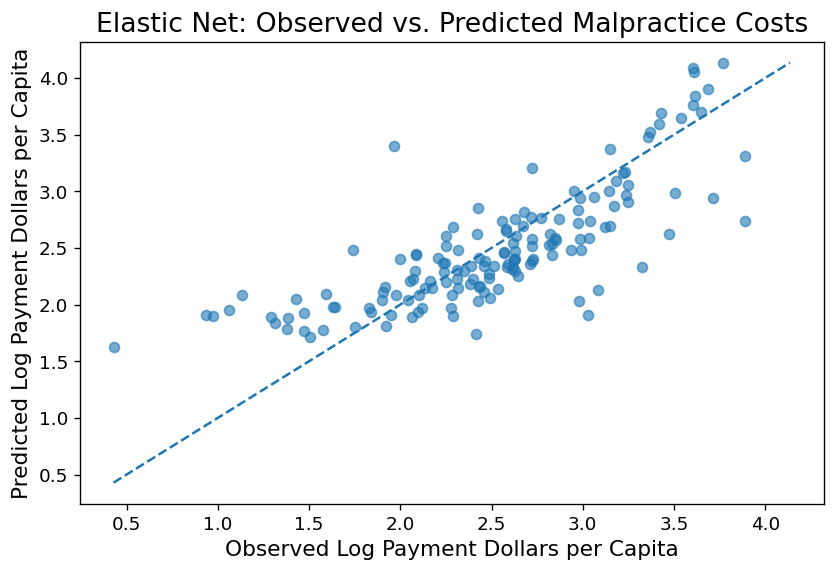

In [197]:
# plot elastic net observed vs predicted values
plt.figure(figsize = (8, 5))

plt.scatter(
    y_test,
    elastic_predictions,
    alpha = 0.6
)

prediction_min = min(
    y_test.min(),
    elastic_predictions.min()
)

prediction_max = max(
    y_test.max(),
    elastic_predictions.max()
)

plt.plot(
    [prediction_min, prediction_max],
    [prediction_min, prediction_max],
    linestyle = "--"
)

plt.title("Elastic Net: Observed vs. Predicted Malpractice Costs")
plt.xlabel("Observed Log Payment Dollars per Capita")
plt.ylabel("Predicted Log Payment Dollars per Capita")

plt.savefig(
    f"{FIGURE_FOLDER}/elastic_observed_vs_predicted.png",
    bbox_inches = "tight"
)

plt.show()

### Observed vs. Predicted Malpractice Costs

The observed-versus-predicted plot shows a clear positive relationship between actual and predicted log malpractice payment dollars per capita during the 2023–2025 test period. Most observations fall reasonably close to the diagonal reference line, consistent with the test R-squared of approximately 0.614. The model nevertheless shows larger prediction errors for several observations at both the low and high ends of the outcome distribution. In particular, predictions appear somewhat compressed toward the center of the distribution, which is consistent with the shrinkage imposed by regularization. The model therefore captures the broad variation in future malpractice costs but is less successful at reproducing some unusually low or high state-year outcomes. This pattern suggests useful predictive performance without implying that the model can precisely forecast every individual state-year.

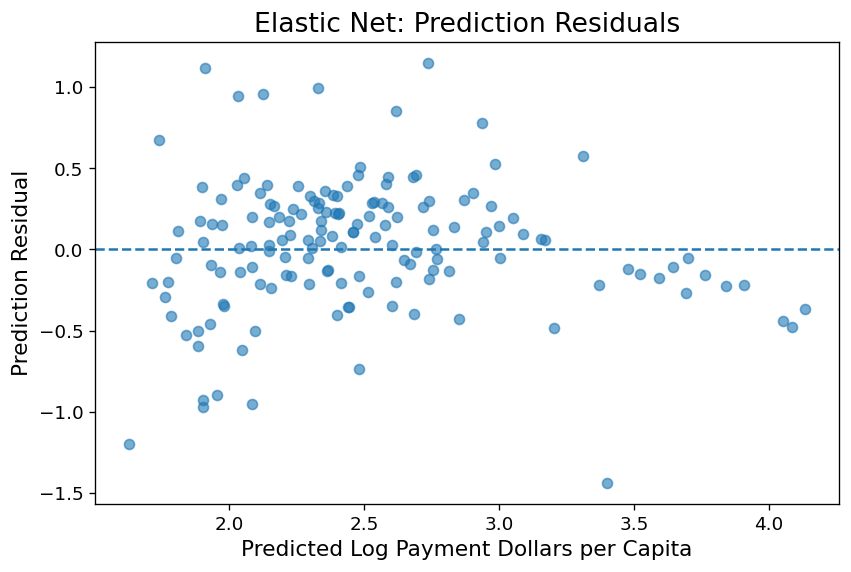

In [198]:
# calculate elastic net prediction residuals
elastic_residuals = (
    y_test.values - elastic_predictions
)

plt.figure(figsize = (8, 5))

plt.scatter(
    elastic_predictions,
    elastic_residuals,
    alpha = 0.6
)

plt.axhline(
    y = 0,
    linestyle = "--"
)

plt.title("Elastic Net: Prediction Residuals")
plt.xlabel("Predicted Log Payment Dollars per Capita")
plt.ylabel("Prediction Residual")

plt.savefig(
    f"{FIGURE_FOLDER}/elastic_prediction_residuals.png",
    bbox_inches = "tight"
)

plt.show()

### Elastic Net Prediction Residuals

The prediction residuals are generally distributed around zero, indicating that the Elastic Net model does not consistently overpredict or underpredict malpractice costs across most of the prediction range. However, several larger positive and negative residuals remain, showing that some state-years were substantially more difficult to predict than others. Residual variation is greater through portions of the middle prediction range, while observations at the highest predicted values tend to have negative residuals. This indicates some tendency for the model to overpredict actual costs among state-years receiving the highest predicted malpractice-cost values. These deviations are consistent with the shrinkage behavior of a strongly regularized model, which tends to pull predictions away from extreme values. Overall, the residual plot suggests reasonable predictive behavior while identifying limitations in predicting unusually extreme outcomes.

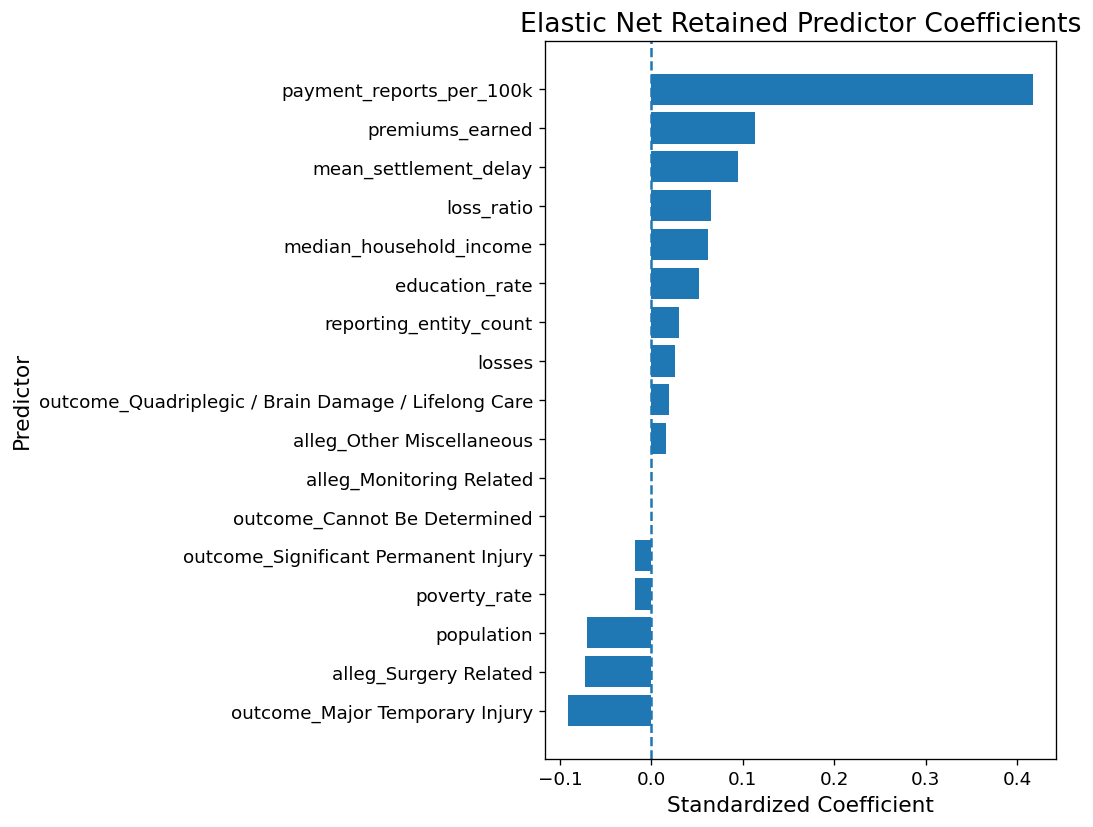

In [199]:
# plot retained elastic net coefficients
elastic_retained = elastic_coefficients[
    elastic_coefficients["Coefficient"] != 0
].copy()

elastic_retained = elastic_retained.sort_values(
    "Coefficient"
)

plt.figure(figsize = (9, 7))

plt.barh(
    elastic_retained["Predictor"],
    elastic_retained["Coefficient"]
)

plt.axvline(
    x = 0,
    linestyle = "--"
)

plt.title("Elastic Net Retained Predictor Coefficients")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Predictor")

plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/elastic_coefficients.png",
    bbox_inches = "tight"
)

plt.show()

### Retained Predictor Importance

The retained-coefficient plot demonstrates that payment reports per 100,000 residents was the dominant predictor in the final Elastic Net model, with a substantially larger standardized coefficient than any other retained feature. Premiums earned and mean settlement delay provided the next-largest positive contributions, while loss ratio, household income, and education rate also retained positive coefficients. Major temporary injury, surgery-related allegations, and population had the largest negative retained coefficients. The strong concentration of predictive weight in a relatively small number of variables is consistent with the Lasso-style solution selected during cross-validation. Because the coefficients were estimated from standardized predictors, their relative magnitudes provide a useful indication of predictive contribution within the fitted model. However, coefficient direction and magnitude should be interpreted as predictive associations rather than evidence of causal relationships.

In [200]:
# calculate test performance by year
elastic_test_results = elastic_test[
    ["state", "year", "log_payment_dollars_per_capita"]
].copy()

elastic_test_results["predicted"] = elastic_predictions

yearly_elastic_results = []

for year in sorted(
    elastic_test_results["year"].unique()
):
    year_data = elastic_test_results[
        elastic_test_results["year"] == year
    ]

    yearly_elastic_results.append({
        "Year": year,
        "R_squared": r2_score(
            year_data["log_payment_dollars_per_capita"],
            year_data["predicted"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                year_data["log_payment_dollars_per_capita"],
                year_data["predicted"]
            )
        ),
        "MAE": mean_absolute_error(
            year_data["log_payment_dollars_per_capita"],
            year_data["predicted"]
        )
    })

elastic_yearly_performance = pd.DataFrame(
    yearly_elastic_results
)

elastic_yearly_performance.round(4)

,Year,R_squared,RMSE,MAE
0,2023,0.5705,0.3878,0.2876
1,2024,0.5766,0.4561,0.3331
2,2025,0.6836,0.3647,0.2894


In [203]:
# prepare yearly elastic net performance table for saving
elastic_yearly_display = (
    elastic_yearly_performance.copy()
)

elastic_yearly_display[
    [
        "R_squared",
        "RMSE",
        "MAE"
    ]
] = elastic_yearly_display[
    [
        "R_squared",
        "RMSE",
        "MAE"
    ]
].round(4)

elastic_yearly_display = elastic_yearly_display.rename(
    columns = {
        "R_squared": "R-squared"
    }
)

elastic_yearly_display = elastic_yearly_display.set_index(
    "Year"
)

save_table(
    elastic_yearly_display,
    "elastic_yearly_performance.png"
)

### Elastic Net Performance by Test Year

Predictive performance remained relatively stable across the three years in the temporal test period. The model achieved R-squared values of approximately 0.576 in 2023, 0.577 in 2024, and 0.684 in 2025, indicating that predictive performance did not deteriorate as the test observations became farther removed from the training period. RMSE was highest in 2024 at approximately 0.456, compared with 0.388 in 2023 and 0.365 in 2025. MAE showed a similar pattern, increasing to approximately 0.333 in 2024 before declining to 0.289 in 2025. The stronger performance in 2025 suggests that the overall test results are not being driven solely by observations immediately adjacent to the training period. Taken together, the yearly metrics provide additional evidence that the model's predictive performance was reasonably stable across the held-out period.

### Elastic Net Modeling Approach

Elastic Net regression was used as a predictive complement to the inferential fixed-effects analysis, with log malpractice payment dollars per capita serving as the prediction target. A broad set of 38 malpractice, insurance, socioeconomic, practitioner, allegation, and injury-outcome variables was initially considered, while variables directly derived from malpractice payment amounts were excluded to avoid target leakage. Rather than randomly dividing the state-year panel, observations from 2011–2022 were used for model training and 2023–2025 were reserved as an untouched temporal test set, allowing model performance to be evaluated on later years not used during training. All predictors were standardized using parameters estimated only from the training data because Elastic Net regularization is sensitive to differences in variable scale and because using test-period information during preprocessing would introduce data leakage. Time-aware cross-validation was used within the training period to select the regularization strength and L1/L2 mixture. Cross-validation evaluated multiple L1 ratios ranging from 0.1 to 1.0, allowing the model to determine whether a mixture of Ridge and Lasso penalties or a more sparse Lasso-style solution provided better predictive performance. This approach allowed correlated and potentially redundant predictors to be considered simultaneously while shrinking weak predictors toward zero and retaining variables that contributed greater predictive information.

### Elastic Net Results and Implications

The Elastic Net model was trained using state-year observations from 2011–2022 and evaluated on an untouched temporal test set containing observations from 2023–2025. Cross-validation selected an alpha of approximately 0.0069 and an L1 ratio of 1.0, indicating that the optimal regularization strategy corresponded to the Lasso end of the Elastic Net spectrum. The model retained 17 of the 38 candidate predictors while shrinking the remaining 21 coefficients to zero, demonstrating substantial feature selection. Malpractice payment reports per 100,000 residents had the largest retained standardized coefficient, followed by premiums earned and mean settlement delay, indicating that these variables provided particularly strong predictive information for malpractice payment costs. On the 2023–2025 test set, the model achieved an R-squared of approximately 0.614, an RMSE of 0.405, and an MAE of 0.303 on the log payment-per-capita scale. The observed-versus-predicted results show that the model captured much of the overall variation in future malpractice costs, although prediction errors remained for some state-years and predictions tended to be less accurate at the extremes. These results indicate that a regularized linear model can provide meaningful out-of-sample prediction of state malpractice costs while simultaneously reducing a broad set of candidate predictors to a smaller subset with greater predictive value.

# Model 4: Random Forest / Gradient Boosting

## Random Forest

### Model-Specific Data Preparation

In [204]:
# define random forest predictors
rf_predictors = elastic_predictors.copy()

rf_vars = [
    "state",
    "year",
    "payment_dollars_per_capita"
] + rf_predictors

rf_df = df[rf_vars].copy()

# create random forest target
rf_df["log_payment_dollars_per_capita"] = np.log(
    rf_df["payment_dollars_per_capita"]
)

print(rf_df.shape)
rf_df.head()

(765, 42)


,state,year,payment_dollars_per_capita,payment_reports_per_100k,mean_settlement_delay,prac_Dentistry,prac_Nursing,prac_Other,prac_Physician,prac_Physician Assistant,...,premiums_written,premiums_earned,losses,defense_costs,loss_ratio,population,median_household_income,poverty_rate,education_rate,log_payment_dollars_per_capita
0,AK,2011,8.869619,2.354153,3.294118,2,2,2,10,1,...,22703036.0,22569754.0,5283794.0,4437422.0,43.07,722128.0,67825,10.455394,26.367043,2.182632
1,AK,2012,9.490816,2.464258,3.833333,4,2,0,11,1,...,22107229.0,21852515.0,3583030.0,4453763.0,36.78,730443.0,67712,10.117271,28.008110,2.250325
2,AK,2013,5.542569,2.035090,4.066667,2,2,2,9,0,...,22443385.0,22176485.0,-1901825.0,3572261.0,7.53,737068.0,72237,9.329040,27.971573,1.712458
3,AK,2014,9.609077,2.987982,4.272727,0,3,4,15,0,...,23415271.0,22537843.0,5810998.0,5399730.0,49.74,736283.0,71583,11.233721,28.004790,2.262708
4,AK,2015,10.240706,2.576278,3.684211,2,3,0,13,1,...,23547386.0,23146743.0,2093624.0,4770763.0,29.66,737498.0,73355,10.340680,29.693114,2.326371


In [205]:
# create temporal random forest training and test sets
rf_train = rf_df[
    rf_df["year"] <= 2022
].copy()

rf_test = rf_df[
    rf_df["year"] >= 2023
].copy()

print(
    "Training shape:",
    rf_train.shape
)

print(
    "Test shape:",
    rf_test.shape
)

print(
    "Training years:",
    rf_train["year"].min(),
    "-",
    rf_train["year"].max()
)

print(
    "Test years:",
    rf_test["year"].min(),
    "-",
    rf_test["year"].max()
)

Training shape: (612, 42)
Test shape: (153, 42)
Training years: 2011 - 2022
Test years: 2023 - 2025


In [206]:
# separate random forest predictors and target
X_rf_train = rf_train[
    rf_predictors
].copy()

X_rf_test = rf_test[
    rf_predictors
].copy()

y_rf_train = rf_train[
    "log_payment_dollars_per_capita"
].copy()

y_rf_test = rf_test[
    "log_payment_dollars_per_capita"
].copy()

print("X_rf_train:", X_rf_train.shape)
print("X_rf_test:", X_rf_test.shape)
print("y_rf_train:", y_rf_train.shape)
print("y_rf_test:", y_rf_test.shape)

X_rf_train: (612, 38)
X_rf_test: (153, 38)
y_rf_train: (612,)
y_rf_test: (153,)


In [207]:
X_rf_train: (612, 38)
X_rf_test: (153, 38)
y_rf_train: (612,)
y_rf_test: (153,)

In [208]:
# import random forest regressor
from sklearn.ensemble import RandomForestRegressor

In [209]:
# fit baseline random forest model
rf_baseline = RandomForestRegressor(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_baseline.fit(
    X_rf_train,
    y_rf_train
)

,n_estimators,500
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [210]:
# generate baseline random forest predictions
rf_baseline_predictions = rf_baseline.predict(
    X_rf_test
)

In [211]:
# evaluate baseline random forest performance
rf_baseline_r2 = r2_score(
    y_rf_test,
    rf_baseline_predictions
)

rf_baseline_rmse = np.sqrt(
    mean_squared_error(
        y_rf_test,
        rf_baseline_predictions
    )
)

rf_baseline_mae = mean_absolute_error(
    y_rf_test,
    rf_baseline_predictions
)

print(
    "Baseline Random Forest R-squared:",
    rf_baseline_r2
)

print(
    "Baseline Random Forest RMSE:",
    rf_baseline_rmse
)

print(
    "Baseline Random Forest MAE:",
    rf_baseline_mae
)

Baseline Random Forest R-squared: 0.6481908298823631
Baseline Random Forest RMSE: 0.38623010205615105
Baseline Random Forest MAE: 0.2944352500873011


In [212]:
# evaluate random forest training performance
rf_train_predictions = rf_baseline.predict(
    X_rf_train
)

rf_train_r2 = r2_score(
    y_rf_train,
    rf_train_predictions
)

rf_train_rmse = np.sqrt(
    mean_squared_error(
        y_rf_train,
        rf_train_predictions
    )
)

rf_train_mae = mean_absolute_error(
    y_rf_train,
    rf_train_predictions
)

print(
    "Training R-squared:",
    rf_train_r2
)

print(
    "Training RMSE:",
    rf_train_rmse
)

print(
    "Training MAE:",
    rf_train_mae
)

Training R-squared: 0.9658254196115643
Training RMSE: 0.11500732332363113
Training MAE: 0.08075039115067514


In [213]:
# import random forest tuning tools
from sklearn.model_selection import GridSearchCV

In [214]:
# sort random forest training data chronologically
rf_train_order = rf_train.sort_values(
    ["year", "state"]
).index

X_rf_train_cv = X_rf_train.loc[
    rf_train_order
]

y_rf_train_cv = y_rf_train.loc[
    rf_train_order
]

In [215]:
# create time-aware random forest cross-validation
rf_cv = TimeSeriesSplit(
    n_splits = 5
)

In [216]:
# define random forest tuning grid
rf_param_grid = {
    "n_estimators": [
        300,
        500
    ],
    "max_depth": [
        5,
        10,
        None
    ],
    "min_samples_leaf": [
        1,
        2,
        4
    ],
    "max_features": [
        "sqrt",
        0.5,
        1.0
    ]
}

In [217]:
# tune random forest model
rf_grid_search = GridSearchCV(
    estimator = RandomForestRegressor(
        random_state = 42,
        n_jobs = -1
    ),
    param_grid = rf_param_grid,
    scoring = "neg_mean_squared_error",
    cv = rf_cv,
    n_jobs = -1
)

rf_grid_search.fit(
    X_rf_train_cv,
    y_rf_train_cv
)

print(
    "Best parameters:",
    rf_grid_search.best_params_
)

print(
    "Best cross-validation RMSE:",
    np.sqrt(
        -rf_grid_search.best_score_
    )
)

Best parameters: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}
Best cross-validation RMSE: 0.3395413321143724


In [218]:
# retrieve tuned random forest
rf_tuned = rf_grid_search.best_estimator_

rf_tuned_predictions = rf_tuned.predict(
    X_rf_test
)

In [219]:
# evaluate tuned random forest performance
rf_tuned_r2 = r2_score(
    y_rf_test,
    rf_tuned_predictions
)

rf_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_rf_test,
        rf_tuned_predictions
    )
)

rf_tuned_mae = mean_absolute_error(
    y_rf_test,
    rf_tuned_predictions
)

print(
    "Tuned Random Forest R-squared:",
    rf_tuned_r2
)

print(
    "Tuned Random Forest RMSE:",
    rf_tuned_rmse
)

print(
    "Tuned Random Forest MAE:",
    rf_tuned_mae
)

Tuned Random Forest R-squared: 0.6308221929922144
Tuned Random Forest RMSE: 0.3956492383314611
Tuned Random Forest MAE: 0.3021018661299836


In [220]:
# evaluate tuned random forest training performance
rf_tuned_train_predictions = rf_tuned.predict(
    X_rf_train
)

rf_tuned_train_r2 = r2_score(
    y_rf_train,
    rf_tuned_train_predictions
)

rf_tuned_train_rmse = np.sqrt(
    mean_squared_error(
        y_rf_train,
        rf_tuned_train_predictions
    )
)

rf_tuned_train_mae = mean_absolute_error(
    y_rf_train,
    rf_tuned_train_predictions
)

print(
    "Tuned training R-squared:",
    rf_tuned_train_r2
)

print(
    "Tuned training RMSE:",
    rf_tuned_train_rmse
)

print(
    "Tuned training MAE:",
    rf_tuned_train_mae
)

Tuned training R-squared: 0.9486671339784686
Tuned training RMSE: 0.14095213440181292
Tuned training MAE: 0.10412621406203185


## Gradient Boosting

moving on to gradient boosting because tuning radom forest did not improve over the baseline

In [222]:
# import gradient boosting regressor
from sklearn.ensemble import GradientBoostingRegressor

In [223]:
# fit baseline gradient boosting model
gb_baseline = GradientBoostingRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42
)

gb_baseline.fit(
    X_rf_train,
    y_rf_train
)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [224]:
# generate baseline gradient boosting predictions
gb_baseline_predictions = gb_baseline.predict(
    X_rf_test
)

In [225]:
# evaluate baseline gradient boosting test performance
gb_baseline_r2 = r2_score(
    y_rf_test,
    gb_baseline_predictions
)

gb_baseline_rmse = np.sqrt(
    mean_squared_error(
        y_rf_test,
        gb_baseline_predictions
    )
)

gb_baseline_mae = mean_absolute_error(
    y_rf_test,
    gb_baseline_predictions
)

print(
    "Baseline Gradient Boosting R-squared:",
    gb_baseline_r2
)

print(
    "Baseline Gradient Boosting RMSE:",
    gb_baseline_rmse
)

print(
    "Baseline Gradient Boosting MAE:",
    gb_baseline_mae
)

Baseline Gradient Boosting R-squared: 0.6800826967280996
Baseline Gradient Boosting RMSE: 0.3683082154501978
Baseline Gradient Boosting MAE: 0.27420414243128993


In [226]:
# evaluate gradient boosting training performance
gb_train_predictions = gb_baseline.predict(
    X_rf_train
)

gb_train_r2 = r2_score(
    y_rf_train,
    gb_train_predictions
)

gb_train_rmse = np.sqrt(
    mean_squared_error(
        y_rf_train,
        gb_train_predictions
    )
)

gb_train_mae = mean_absolute_error(
    y_rf_train,
    gb_train_predictions
)

print(
    "Training R-squared:",
    gb_train_r2
)

print(
    "Training RMSE:",
    gb_train_rmse
)

print(
    "Training MAE:",
    gb_train_mae
)

Training R-squared: 0.9388928203281489
Training RMSE: 0.153787139984813
Training MAE: 0.12040312300957186


In [227]:
# compare predictive model performance
model4_comparison = pd.DataFrame({
    "Model": [
        "Elastic Net",
        "Baseline Random Forest",
        "Tuned Random Forest",
        "Baseline Gradient Boosting"
    ],
    "Test R-squared": [
        elastic_r2,
        rf_baseline_r2,
        rf_tuned_r2,
        gb_baseline_r2
    ],
    "Test RMSE": [
        elastic_rmse,
        rf_baseline_rmse,
        rf_tuned_rmse,
        gb_baseline_rmse
    ],
    "Test MAE": [
        elastic_mae,
        rf_baseline_mae,
        rf_tuned_mae,
        gb_baseline_mae
    ]
})

model4_comparison.round(4)

,Model,Test R-squared,Test RMSE,Test MAE
0,Elastic Net,0.6137,0.4047,0.3033
1,Baseline Random Forest,0.6482,0.3862,0.2944
2,Tuned Random Forest,0.6308,0.3956,0.3021
3,Baseline Gradient Boosting,0.6801,0.3683,0.2742


In [228]:
# define gradient boosting tuning grid
gb_param_grid = {
    "n_estimators": [
        100,
        200,
        300
    ],
    "learning_rate": [
        0.03,
        0.05,
        0.1
    ],
    "max_depth": [
        2,
        3,
        4
    ],
    "min_samples_leaf": [
        1,
        2,
        4
    ]
}

In [229]:
# tune gradient boosting model
gb_grid_search = GridSearchCV(
    estimator = GradientBoostingRegressor(
        random_state = 42
    ),
    param_grid = gb_param_grid,
    scoring = "neg_mean_squared_error",
    cv = rf_cv,
    n_jobs = -1
)

gb_grid_search.fit(
    X_rf_train_cv,
    y_rf_train_cv
)

print(
    "Best parameters:",
    gb_grid_search.best_params_
)

print(
    "Best cross-validation RMSE:",
    np.sqrt(
        -gb_grid_search.best_score_
    )
)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}
Best cross-validation RMSE: 0.33419893898338954


In [230]:
# retrieve tuned gradient boosting model
gb_tuned = gb_grid_search.best_estimator_

gb_tuned_predictions = gb_tuned.predict(
    X_rf_test
)

In [231]:
# evaluate tuned gradient boosting performance
gb_tuned_r2 = r2_score(
    y_rf_test,
    gb_tuned_predictions
)

gb_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_rf_test,
        gb_tuned_predictions
    )
)

gb_tuned_mae = mean_absolute_error(
    y_rf_test,
    gb_tuned_predictions
)

print(
    "Tuned Gradient Boosting R-squared:",
    gb_tuned_r2
)

print(
    "Tuned Gradient Boosting RMSE:",
    gb_tuned_rmse
)

print(
    "Tuned Gradient Boosting MAE:",
    gb_tuned_mae
)

Tuned Gradient Boosting R-squared: 0.6869167515351909
Tuned Gradient Boosting RMSE: 0.3643530898069232
Tuned Gradient Boosting MAE: 0.2652824079111302


In [232]:
# evaluate tuned gradient boosting training performance
gb_tuned_train_predictions = gb_tuned.predict(
    X_rf_train
)

gb_tuned_train_r2 = r2_score(
    y_rf_train,
    gb_tuned_train_predictions
)

gb_tuned_train_rmse = np.sqrt(
    mean_squared_error(
        y_rf_train,
        gb_tuned_train_predictions
    )
)

gb_tuned_train_mae = mean_absolute_error(
    y_rf_train,
    gb_tuned_train_predictions
)

print(
    "Tuned training R-squared:",
    gb_tuned_train_r2
)

print(
    "Tuned training RMSE:",
    gb_tuned_train_rmse
)

print(
    "Tuned training MAE:",
    gb_tuned_train_mae
)

Tuned training R-squared: 0.9768759812149885
Tuned training RMSE: 0.09460314124848301
Tuned training MAE: 0.07533626546621608


In [233]:
# compare final predictive model performance
predictive_model_comparison = pd.DataFrame({
    "Model": [
        "Elastic Net",
        "Baseline Random Forest",
        "Tuned Random Forest",
        "Baseline Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "Test R-squared": [
        elastic_r2,
        rf_baseline_r2,
        rf_tuned_r2,
        gb_baseline_r2,
        gb_tuned_r2
    ],
    "Test RMSE": [
        elastic_rmse,
        rf_baseline_rmse,
        rf_tuned_rmse,
        gb_baseline_rmse,
        gb_tuned_rmse
    ],
    "Test MAE": [
        elastic_mae,
        rf_baseline_mae,
        rf_tuned_mae,
        gb_baseline_mae,
        gb_tuned_mae
    ]
})

predictive_model_comparison.round(4)

,Model,Test R-squared,Test RMSE,Test MAE
0,Elastic Net,0.6137,0.4047,0.3033
1,Baseline Random Forest,0.6482,0.3862,0.2944
2,Tuned Random Forest,0.6308,0.3956,0.3021
3,Baseline Gradient Boosting,0.6801,0.3683,0.2742
4,Tuned Gradient Boosting,0.6869,0.3644,0.2653


In [241]:
# prepare predictive model comparison table for saving
predictive_comparison_display = (
    predictive_model_comparison.copy()
)

predictive_comparison_display[
    [
        "Test R-squared",
        "Test RMSE",
        "Test MAE"
    ]
] = predictive_comparison_display[
    [
        "Test R-squared",
        "Test RMSE",
        "Test MAE"
    ]
].round(4)

predictive_comparison_display = (
    predictive_comparison_display
    .set_index("Model")
)

save_table(
    predictive_comparison_display,
    "predictive_model_comparison.png"
)

### diagnostics and interprestations

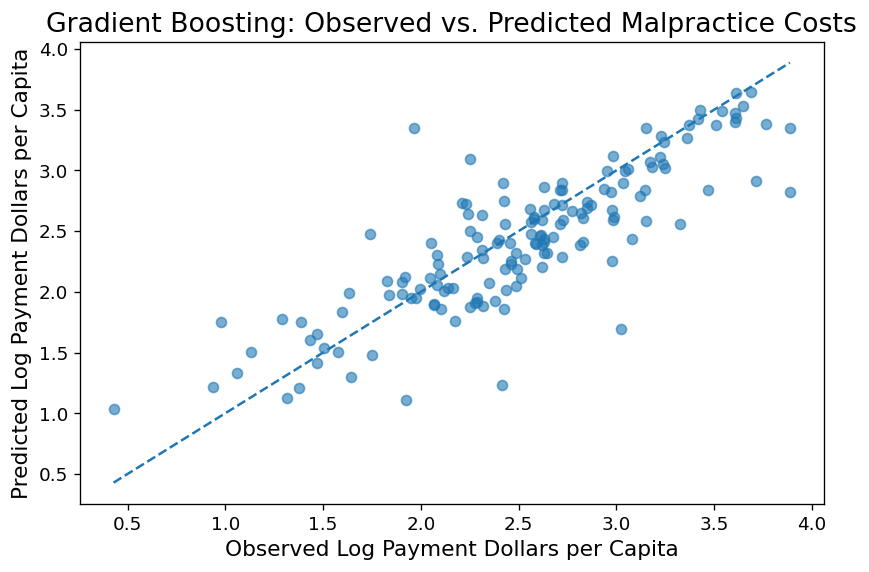

In [234]:
# plot gradient boosting observed vs predicted values
plt.figure(figsize = (8, 5))

plt.scatter(
    y_rf_test,
    gb_tuned_predictions,
    alpha = 0.6
)

gb_prediction_min = min(
    y_rf_test.min(),
    gb_tuned_predictions.min()
)

gb_prediction_max = max(
    y_rf_test.max(),
    gb_tuned_predictions.max()
)

plt.plot(
    [gb_prediction_min, gb_prediction_max],
    [gb_prediction_min, gb_prediction_max],
    linestyle = "--"
)

plt.title("Gradient Boosting: Observed vs. Predicted Malpractice Costs")
plt.xlabel("Observed Log Payment Dollars per Capita")
plt.ylabel("Predicted Log Payment Dollars per Capita")

plt.savefig(
    f"{FIGURE_FOLDER}/gb_observed_vs_predicted.png",
    bbox_inches = "tight"
)

plt.show()

### Gradient Boosting Observed vs. Predicted Costs

The observed-versus-predicted plot shows a strong positive relationship between actual and predicted malpractice payment costs in the 2023–2025 test period. Most observations fall relatively close to the diagonal reference line, consistent with the tuned model's test R-squared of approximately 0.687. Prediction errors remain for several state-years, particularly among observations with unusually high or low malpractice costs. However, the model captures the overall distribution more closely than the other predictive models evaluated in the analysis. The tuned Gradient Boosting model also achieved lower RMSE and MAE than both Random Forest and Elastic Net. These results indicate that nonlinear relationships and interactions among the predictors provide additional predictive information beyond the regularized linear structure used by Elastic Net.

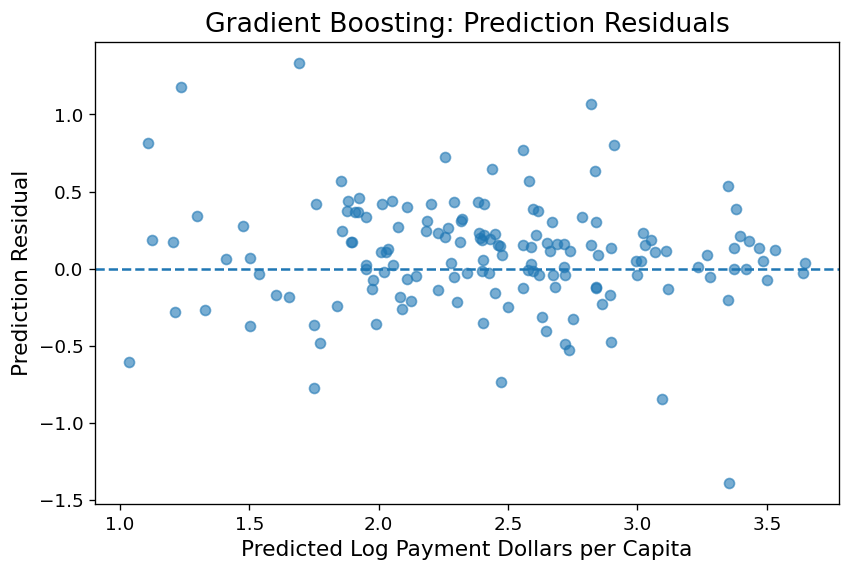

In [235]:
# calculate gradient boosting prediction residuals
gb_residuals = (
    y_rf_test.values - gb_tuned_predictions
)

plt.figure(figsize = (8, 5))

plt.scatter(
    gb_tuned_predictions,
    gb_residuals,
    alpha = 0.6
)

plt.axhline(
    y = 0,
    linestyle = "--"
)

plt.title("Gradient Boosting: Prediction Residuals")
plt.xlabel("Predicted Log Payment Dollars per Capita")
plt.ylabel("Prediction Residual")

plt.savefig(
    f"{FIGURE_FOLDER}/gb_prediction_residuals.png",
    bbox_inches = "tight"
)

plt.show()

### Gradient Boosting Prediction Residuals

The Gradient Boosting prediction residuals are generally centered around zero across the range of predicted malpractice costs. Most errors are relatively small, although several state-years exhibit larger positive or negative deviations from their predicted values. There is no strong continuous curve in the residual pattern, suggesting that the model captures much of the systematic nonlinear structure available in the predictors. Some larger errors remain at both moderate and high predicted values, demonstrating that individual state-year outcomes can still differ substantially from model expectations. Compared with the overall variation in the outcome, the residual pattern is consistent with the model's relatively strong out-of-sample performance. The remaining errors indicate that important state-year-specific influences on malpractice costs are still not fully represented by the available predictors.

In [236]:
# calculate gradient boosting feature importance
gb_feature_importance = pd.DataFrame({
    "Predictor": rf_predictors,
    "Importance": gb_tuned.feature_importances_
})

gb_feature_importance = gb_feature_importance.sort_values(
    "Importance",
    ascending = False
)

gb_feature_importance.head(15)

,Predictor,Importance
0,payment_reports_per_100k,0.571540
1,mean_settlement_delay,0.080275
37,education_rate,0.066512
34,population,0.049470
31,losses,0.028024
35,median_household_income,0.026000
19,outcome_Death,0.021456
33,loss_ratio,0.016988
27,outcome_Significant Permanent Injury,0.013508
9,alleg_Diagnosis Related,0.012400


In [239]:
# prepare gradient boosting feature importance table for saving
gb_feature_importance_display = (
    gb_feature_importance
    .head(15)
    .copy()
)

gb_feature_importance_display["Importance"] = (
    gb_feature_importance_display["Importance"]
    .map(lambda x: f"{x:.4f}")
)

gb_feature_importance_display = (
    gb_feature_importance_display
    .set_index("Predictor")
)

save_table(
    gb_feature_importance_display,
    "gb_feature_importance_table.png"
)

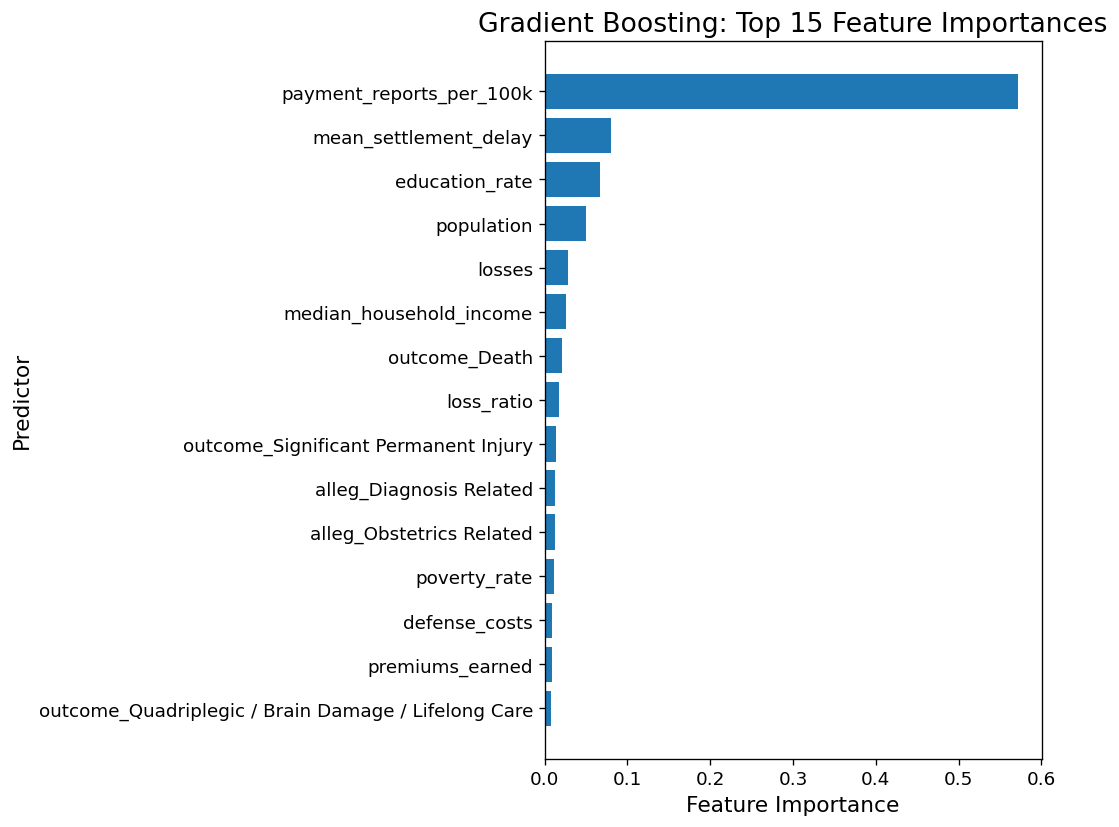

In [237]:
# plot top gradient boosting feature importances
gb_top_features = gb_feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize = (9, 7))

plt.barh(
    gb_top_features["Predictor"],
    gb_top_features["Importance"]
)

plt.title("Gradient Boosting: Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Predictor")

plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/gb_feature_importance.png",
    bbox_inches = "tight"
)

plt.show()

### Gradient Boosting Feature Importance

Malpractice payment reports per 100,000 residents was by far the most influential predictor in the tuned Gradient Boosting model, accounting for approximately 57% of total feature importance. Mean settlement delay was the second-most important feature, followed by education rate, population, losses, and median household income. The dominance of payment-report frequency is consistent with the Elastic Net results, in which the same variable had the largest standardized retained coefficient. This agreement across two substantially different predictive methods provides additional evidence that malpractice report frequency contains particularly strong information for predicting state-level malpractice payment costs. Other socioeconomic, insurance, allegation, and injury-outcome variables contributed smaller amounts of predictive information. Feature importance measures how useful variables were for constructing the model's tree splits and should not be interpreted as the magnitude, direction, or causal effect of a predictor.

In [238]:
# calculate gradient boosting performance by test year
gb_test_results = rf_test[
    ["state", "year", "log_payment_dollars_per_capita"]
].copy()

gb_test_results["predicted"] = gb_tuned_predictions

yearly_gb_results = []

for year in sorted(
    gb_test_results["year"].unique()
):
    year_data = gb_test_results[
        gb_test_results["year"] == year
    ]

    yearly_gb_results.append({
        "Year": year,
        "R_squared": r2_score(
            year_data["log_payment_dollars_per_capita"],
            year_data["predicted"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                year_data["log_payment_dollars_per_capita"],
                year_data["predicted"]
            )
        ),
        "MAE": mean_absolute_error(
            year_data["log_payment_dollars_per_capita"],
            year_data["predicted"]
        )
    })

gb_yearly_performance = pd.DataFrame(
    yearly_gb_results
)

gb_yearly_performance.round(4)

,Year,R_squared,RMSE,MAE
0,2023,0.6307,0.3596,0.2665
1,2024,0.6577,0.4101,0.2997
2,2025,0.7604,0.3174,0.2297


In [240]:
# prepare gradient boosting yearly performance table for saving
gb_yearly_display = gb_yearly_performance.copy()

gb_yearly_display[
    [
        "R_squared",
        "RMSE",
        "MAE"
    ]
] = gb_yearly_display[
    [
        "R_squared",
        "RMSE",
        "MAE"
    ]
].round(4)

gb_yearly_display = gb_yearly_display.rename(
    columns = {
        "R_squared": "R-squared"
    }
)

gb_yearly_display = gb_yearly_display.set_index(
    "Year"
)

save_table(
    gb_yearly_display,
    "gb_yearly_performance.png"
)

### Gradient Boosting Performance by Test Year

The tuned Gradient Boosting model maintained strong predictive performance across all three years of the temporal test period. Test R-squared increased from approximately 0.631 in 2023 to 0.658 in 2024 and 0.760 in 2025, indicating that performance did not deteriorate as predictions moved farther from the training period. RMSE was highest in 2024 at approximately 0.410 and lowest in 2025 at 0.317, while MAE similarly declined to approximately 0.230 in 2025. The particularly strong 2025 performance indicates that the overall model results are not driven solely by observations immediately following the 2011–2022 training period. Instead, the model demonstrated reasonably stable out-of-sample prediction across the complete three-year holdout period. This temporal stability provides additional support for selecting tuned Gradient Boosting as the final predictive model within the Random Forest/Gradient Boosting analysis.

### Random Forest and Gradient Boosting Modeling Approach

Random Forest and Gradient Boosting were evaluated as nonlinear predictive alternatives to the Elastic Net model using the same log malpractice payment dollars per capita outcome and the same set of 38 candidate predictors. To maintain a consistent out-of-sample evaluation, observations from 2011–2022 were used for training and observations from 2023–2025 were reserved as the temporal test set. Unlike Elastic Net, the tree-based predictors were not standardized because decision-tree splits are not sensitive to differences in measurement scale. A baseline Random Forest was fitted first and produced stronger test performance than Elastic Net, although its substantially higher training performance indicated overfitting. Time-aware cross-validation was therefore used to tune Random Forest complexity, but the tuned model did not improve held-out performance relative to the baseline. Gradient Boosting was subsequently evaluated because it builds trees sequentially to correct errors from previous trees and can capture nonlinear relationships differently from Random Forest. Baseline Gradient Boosting outperformed Random Forest, and time-aware tuning produced a further improvement, resulting in the final model with 200 estimators, a learning rate of 0.1, maximum tree depth of 3, and minimum leaf size of 1. The tuned Gradient Boosting model was therefore retained as the final Model 4 specification based on its superior performance on the untouched 2023–2025 test period.

### Random Forest and Gradient Boosting Results and Implications

Among the nonlinear predictive models, tuned Gradient Boosting produced the strongest out-of-sample performance, achieving a test R-squared of approximately 0.687, RMSE of 0.364, and MAE of 0.265. This exceeded the performance of baseline Random Forest, tuned Random Forest, and Elastic Net on the same 2023–2025 temporal test period. Payment reports per 100,000 residents was the dominant Gradient Boosting feature, accounting for approximately 57% of total feature importance, while mean settlement delay, education rate, population, and insurance-related measures provided smaller contributions. The prominence of payment-report frequency across both Gradient Boosting and Elastic Net suggests that the frequency of malpractice events contains particularly strong predictive information about state-level malpractice payment costs. Performance remained stable across the temporal holdout and was strongest in 2025, when the model explained approximately 76% of observed variation. Although the model fitted the training data more closely than the test data, its strong held-out performance indicates that it captured relationships that generalized meaningfully to later state-year observations. These results suggest that nonlinear interactions among malpractice, socioeconomic, and insurance characteristics improve prediction of malpractice costs beyond the regularized linear relationships captured by Elastic Net.